<a href="https://colab.research.google.com/github/jihyeon26/computational-language-technology-hs26/blob/main/stage3/work_packages/stage3_wp3_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3. System Evaluation and Enhancement
Part 1 built the Q&A test set and the text-only RAG baseline; Part 2 added the Stage 1 knowledge graph and answered every test question with both systems. This part measures the quality of those answers, finds where the systems fail, and fixes one of the failures:
1. **Test set and question categories**: the questions are labelled with the three categories of the Q&A session of 30 October (factoid, multi-hop, global), and 30 multi-hop and global questions are drafted and reviewed by hand (23 kept), since the Part 1 questions all come from a single passage.
2. **Answers of the two systems**: the answers saved by Part 2 (text-only and text + graph) are loaded, and the new questions are answered with the same pipelines.
3. **Evaluation with a judge model**: every answer is scored on faithfulness, relevance, context grounding, temporal grounding and correctness by a model that is different from the RAG model.
4. **Human check of the judge**: a sample of the judgments is scored by hand, to know how far the judge can be trusted.
5. **Retrieval diagnosis**: where the answers fail, is it retrieval or generation?
6. **Enhancement**: one limitation observed in the evaluation is addressed with one change to the pipeline, which is evaluated the same way.
7. **Summary**: trade-offs between the systems and what RAG with a knowledge graph brings to trend monitoring in the open-models track.

**Key results**
- **The graph helps a little, and not where it was expected.** Over 236 questions, text + graph RAG scores higher than text-only RAG on every criterion, but only the gain in relevance is reliable (+0.08 on a 1–5 scale, 95% interval [+0.00, +0.15]); the gain in correctness (+0.06, [−0.07, +0.18]) is not. On the 18 multi-hop questions, the category built so that the graph could show its value, the two systems have exactly the same correctness (3.39).
- **The failures are retrieval failures.** When a source article is in the prompt, correctness is 4.2; when it is not, 3.3, and the model answers "the sources do not say" twice as often. Hybrid search puts a source article first for 58% of the factoid questions, 33% of the multi-hop and 20% of the global ones; for the global questions it finds 14% of the articles they need.
- **Re-ranking the retrieved passages with a cross-encoder is the one change that moves correctness**: +0.22 over the text-only baseline ([+0.00, +0.40], p = 0.02), better than the graph (+0.16, p = 0.06), with the same model and prompt. It improves the factoid questions (4.11 → 4.37) and leaves the multi-hop and global ones no better, because it ranks passages one at a time and favours one article over several.
- **Sparse search alone beats the hybrid search of Part 1** on this test set (MRR 0.73 against 0.67), a consequence of questions that share words with their passages even after paraphrasing.
- **The judge is checked, not trusted.** A model of a different family from the RAG model scores every answer; on a blind sample of 30 scored by hand it agrees with the reviewer within one point for 90–97% of the answers but is about 0.4 points more lenient on correctness, and the reviewer sees no difference between the two systems (Section 3.4); a higher reasoning effort shifts both systems alike on correctness and relevance (Section 3.4.1).

## Stage 3 requirements and where they are addressed
The three rows left open by Parts 1 and 2 of the requirements table, and the guidelines of the Q&A session of 30 October, which arrived after the Part 1 test set was finished.

| Requirement (project brief) | Section |
|---|---|
| Integrate the Stage 1 knowledge graph and compare with text-only RAG | 3.2, 3.3 |
| Evaluate faithfulness, relevance, context and temporal grounding | 3.3 |
| Implement and evaluate one RAG enhancement | 3.6 |

| Guideline (Q&A session of 30 October) | Section |
|---|---|
| Label every question by the information needed: factoid, multi-hop, global | 3.1 |
| Paraphrase: questions that do not copy the wording of their source | 3.1, 3.1.1 |
| Realistic user perspectives | 3.1 |
| Multi-hop questions that genuinely require combining several passages | 3.1 |
| Global questions drawn from several passages on a broader topic | 3.1 |
| Validate the Q&A pairs, keeping the reference answer and the source passages | 3.1 |
| Compare per category, rather than assuming graph RAG is superior | 3.3.1, 3.5, 3.6 |

## Contributions

| Team member | Sections | Contribution |
|---|---|---|
| Daliasny Gonzalez Guzman | 3 | multi-hop and global test questions, evaluation with a judge model, human check of the judge, retrieval diagnosis, re-ranking enhancement |

**Cache**: every long step (generation, judging) saves its result on Google Drive (`OUT_DIR`) and loads it at later runs, so the notebook can be re-run without a GPU or an API key once the answers and judgments exist.

## Setup
The notebook runs in Google Colab (a GPU runtime is needed only to generate new answers with the local RAG model; the judge runs through an API). It reads:
- the Stage 1 corpus from the shared Google Drive (`corpus_clean.parquet`), to rebuild the RAG corpus of Part 1;
- the test set, the RAG settings and the saved answers of Parts 1 and 2 from the project repository (`artifacts/stage3_wp1`, `artifacts/stage3_wp2`);
- the key of the judge model from the Colab secrets (`OPENAI_API_KEY`), so that it never appears in the notebook.

In [1]:
# anatoolbox
%pip install -q "anatoolbox[embeddings] @ git+https://github.com/umagira/anatoolbox" openpyxl

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from pathlib import Path
import json
import os
import re
import shutil
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Clone the project repository
    REPO = Path("/content/computational-language-technology-hs26")
    if REPO.exists():
        !git -C {REPO} pull -q
    else:
        !git clone -q https://github.com/jihyeon26/computational-language-technology-hs26.git {REPO}
    # Mount Google Drive (input data and outputs)
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/HSLU/CLT")
    try:
        OPENAI_API_KEY = userdata.get("OPENAI_API_KEY")      # Colab secret (key icon on the left)
    except Exception:                                        # no secret yet: everything except the judge still runs
        OPENAI_API_KEY = None
else:                                                         # local run: CLT_REPO and CLT_DRIVE point to the same folders
    REPO = Path(os.environ["CLT_REPO"])
    DRIVE = Path(os.environ["CLT_DRIVE"])
    OPENAI_API_KEY = os.environ.get("OPENAI_API_KEY")

DATA_DIR = DRIVE / "data/processed"                                   # Stage 1 outputs
RAG_DIR = DRIVE / "extraction_outputs/stage3/wp1/rag"                 # Part 1: corpus file and chunk embeddings
OUT_DIR = DRIVE / "extraction_outputs/stage3/wp3"                     # outputs of this part (also used as cache)
FIG = OUT_DIR / "figures"
for directory in (RAG_DIR, FIG):
    directory.mkdir(parents=True, exist_ok=True)
WP1_ART = REPO / "artifacts/stage3_wp1"                               # Part 1: test set, RAG settings
WP2_ART = REPO / "artifacts/stage3_wp2/graph_rag"                     # Part 2: answers of both systems, retrieval results
WP3_ART = REPO / "artifacts/stage3_wp3"                               # this part: small outputs copied to the repository

RAG_SETTINGS = json.loads((WP1_ART / "rag_settings.json").read_text(encoding="utf-8"))
RAG_MODEL = RAG_SETTINGS["rag_model"]["model"]                        # qwen3:4b-instruct (Ollama)
JUDGE_MODEL = "gpt-5-mini"                                            # judge: a different model family from the RAG model
TYPES = ["factual", "temporal", "relational", "analytical", "comparative"]
CATEGORIES = ["factoid", "multi-hop", "global"]
SYSTEMS = {"text": "text-only RAG", "graph": "text + graph RAG"}

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print(f"RAG model: {RAG_MODEL} | judge model: {JUDGE_MODEL} | key for the judge: {'found' if OPENAI_API_KEY else 'missing'}")

Mounted at /content/drive
RAG model: qwen3:4b-instruct | judge model: gpt-5-mini | key for the judge: found


## 3.1 Test Set and Question Categories
The Q&A session of 30 October asked to label every question by the information needed to answer it, so that the comparison between text-only RAG and graph RAG shows where each one helps:

| Category | Information needed | In the test set |
|---|---|---|
| **factoid / definition** | one passage: a fact or a definition | the 213 questions of Part 1, each drafted from one passage |
| **multi-hop / relational** | two or more passages that have to be connected | 18 new questions, each drafted from passages of two to three different articles |
| **global / summary** | a synthesis across several passages or a broader theme | 5 new questions, each drafted from four or five passages of as many articles on one theme |

The new questions follow the method of Part 1: 30 were drafted by Claude (Anthropic) from the 150 passages of Part 1 (`passages_for_qa.csv`), grouped by model family and event, with a reference answer and one evidence sentence per passage; the five question types of Part 1 are kept. Every question was then reviewed by hand with the criteria of Part 1 (clarity, correctness, answerability, naturalness) and two criteria for the new categories: a multi-hop question must really need all its passages (covering one passage, can the question still be answered?), and a global question must ask for a synthesis rather than one fact. Three measurements supported the review: the share of the answer's content words found in the cited passages, the share found in the best single passage, and the wording overlap between the question and its passages. As in Part 1, questions were kept, edited or dropped (`qa_multihop_reviewed.xlsx`): **20 kept, 3 edited, 7 dropped**. The drops were questions whose second passage was decorative (an unrelated fact glued to a one-passage question), one answered by a single sentence of one passage, one whose answer stated more than its passages, and one definition question mislabelled as global; the edits reworded two questions that copied their passages' wording or referred to an unnamed report, and moved one four-article question from multi-hop to global. The source articles of a question (`source_ids`) are all the articles its passages come from, so retrieval is scored on several relevant articles for the new questions.

In [3]:
# Part 1 test set: single-passage questions
factoid = json.loads((WP1_ART / "qa_reviewed.json").read_text(encoding="utf-8"))
for q in factoid:
    q["category"] = "factoid"

def wp3_file(name):
    # A file of this part: in the repository (artifacts/stage3_wp3) or, before it is pushed, in OUT_DIR on Drive
    return next((p for p in (WP3_ART / name, OUT_DIR / name) if p.exists()), WP3_ART / name)

# New questions after the manual review. REQUIRE_REVIEW stops the notebook rather than evaluating the
# unreviewed draft by mistake; set it to False only to try the notebook out before the review is done.
REQUIRE_REVIEW = True
REVIEWED_XLSX = next((p for name in ("qa_multihop_reviewed.xlsx", "qa_multihop_review.xlsx")
                      if (p := wp3_file(name)).exists()), None)
DRAFT_CSV = wp3_file("qa_multihop_draft.csv")
if REVIEWED_XLSX is not None:
    review = pd.read_excel(REVIEWED_XLSX, sheet_name="qa_multihop", dtype=str).fillna("")
    print(f"Manual review read from {REVIEWED_XLSX}")
else:
    assert not REQUIRE_REVIEW, (
        "The reviewed questions were not found, and the unreviewed draft would be evaluated instead. Put "
        "qa_multihop_reviewed.xlsx in one of these two folders and run again:\n"
        f"  {WP3_ART}\n  {OUT_DIR}\n"
        "(set REQUIRE_REVIEW = False in this cell to run on the draft on purpose.)")
    review = pd.read_csv(DRAFT_CSV, dtype=str).fillna("")
    print("Reviewed file not found: the draft is used, every question counted as kept")
    review["review_status"] = "keep"
review["review_status"] = review["review_status"].str.strip().str.lower().replace("", "keep")
print("Review of the new questions:", review["review_status"].value_counts().to_dict())
kept = review[review["review_status"].isin(["keep", "edit"])]
new_questions = [{"id": r["qa_id"], "type": r["type"], "category": r["category"], "question": r["question"],
                  "reference_answer": r["reference_answer"], "source_ids": json.loads(r["source_ids"]),
                  "passage_ids": json.loads(r["passage_ids"]), "date": r["dates"].split(";")[0].strip()}
                 for _, r in kept.iterrows()]
(OUT_DIR / "qa_multihop.json").write_text(json.dumps(new_questions, indent=1, ensure_ascii=False), encoding="utf-8")

EVAL_SET = factoid + new_questions
BY_ID = {q["id"]: q for q in EVAL_SET}
(OUT_DIR / "test_set_v2.json").write_text(json.dumps(EVAL_SET, indent=1, ensure_ascii=False), encoding="utf-8")
counts = pd.crosstab(pd.Series([q["category"] for q in EVAL_SET], name="category"),
                     pd.Series([q["type"] for q in EVAL_SET], name="type"), margins=True, margins_name="total")
display(counts.reindex(CATEGORIES + ["total"]).reindex(columns=TYPES + ["total"]))
print(f"Test set: {len(EVAL_SET)} questions | source articles per question: "
      f"{pd.Series([len(q['source_ids']) for q in EVAL_SET]).value_counts().sort_index().to_dict()}")

Manual review read from /content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage3/wp3/qa_multihop_reviewed.xlsx
Review of the new questions: {'keep': 20, 'drop': 7, 'edit': 3}


type,factual,temporal,relational,analytical,comparative,total
category,,,,,,
factoid,57,38,48,27,43,213
multi-hop,2,4,3,8,1,18
global,0,2,2,1,0,5
total,59,44,53,36,44,236


Test set: 236 questions | source articles per question: {1: 213, 2: 15, 3: 3, 4: 3, 5: 2}


The test set has 236 questions: the 213 single-passage questions of Part 1, all factoid by the definition of the Q&A session, and 23 new ones, 18 multi-hop and 5 global. The review of the 30 drafted questions kept 20, edited 3 and dropped 7; the drops are the sign that the two new criteria bite: six of the seven dropped questions read well and had a correct answer, and failed on *needing* their second passage or on sounding like a question a reader would ask; the seventh was dropped because its answer stated more than its passages. The five types of Part 1 are all present among the multi-hop questions; the global questions have no factual and no comparative one, but the distribution is different: analytical questions are 13% of the factoid set and 39% of the new one, because connecting two articles usually asks *why* or *how*, not *when*. The source articles per question are the other difference: every Part 1 question has one, the new ones have two to five, so retrieval is scored on several relevant articles for them, and hit@k is read next to recall@k from Section 3.5 on. The word *relational* appears in both labelings and means two different things: the Part 1 type says the question asks about a relation, the category says the relation is stated across two passages; 53 questions are relational by type, 3 of them multi-hop by category.

### 3.1.1 How close are the questions to their passages?
The Q&A session also warned against questions that reuse the wording of their passage: retrieval then finds the passage by its words and the evaluation is too optimistic. The share of a question's content words that appear in its source passages measures this (stop words and the model names, which a question has to keep, are left out). A low share means the question is a paraphrase; the new questions are compared with those of Part 1.

In [4]:
passages = pd.read_csv(WP1_ART / "passages_for_qa.csv").set_index("passage_id")
lexicon = json.loads((REPO / "artifacts/stage1_wp1/lexicon/open_models_lexicon.json").read_text(encoding="utf-8"))
STOP = set("""a an the and or of to in on for with by from at as is are was were be been being what which who whom whose when
where why how did do does done has have had having it its this that these those than then there their they them he she his
her we you your our i me my not no also into about after before between over under during according say said says report
reported article articles model models ai company companies new one two three first last more most much many some any
each per""".split())
NAMES = {t for f in lexicon["families"].values() for t in re.findall(r"[a-z0-9]+", f["label"].lower())} | {"openai", "google", "meta", "microsoft", "nvidia", "alibaba", "deepseek", "mistral", "anthropic", "hugging", "face"}
words = lambda text: {w for w in re.findall(r"[a-z0-9][a-z0-9\-\.]*", str(text).lower())} - STOP - NAMES

def overlap(q):
    ids = q.get("passage_ids") or [q["passage_id"]]
    source = set().union(*(words(passages.loc[p, "text"]) for p in ids if p in passages.index))
    content = words(q["question"])
    return len(content & source) / len(content) if content else np.nan

overlaps = pd.DataFrame({"category": [q["category"] for q in EVAL_SET], "type": [q["type"] for q in EVAL_SET],
                         "overlap": [overlap(q) for q in EVAL_SET]})
display(overlaps.groupby("category")["overlap"].describe()[["count", "mean", "50%", "min", "max"]].round(2)
        .reindex(CATEGORIES).rename(columns={"50%": "median"}))
display(overlaps.groupby("type")["overlap"].mean().round(2).reindex(TYPES).to_frame("mean overlap").T)

,count,mean,median,min,max
category,,,,,
factoid,213.0,0.58,0.67,0.0,1.00
multi-hop,18.0,0.48,0.45,0.2,0.80
global,5.0,0.42,0.50,0.2,0.67


type,factual,temporal,relational,analytical,comparative
mean overlap,0.65,0.47,0.56,0.57,0.57


The questions reuse about half of the content words of their passages: a mean overlap of 0.58 for the factoid questions (median 0.67), 0.48 for the multi-hop and 0.42 for the global ones. The new questions are therefore further from the wording of their sources than those of Part 1, in part because the review reworded the question with the highest overlap, which used every content word of its passage. The maximum for the factoid questions is 1.00, so some Part 1 questions can be found by their words alone; the professor's warning that this makes retrieval "artificially easy" applies to them, and Section 3.5 shows its effect: sparse (word-based) search outperforms the hybrid search on this test set. By type, factual questions have the highest overlap (0.65) and temporal questions the lowest (0.47), since a question about *when* does not repeat the date it asks for. The overlap is a property of the test set, not of the systems, and it is the same for both, so it does not bias their comparison; it does make the absolute retrieval figures optimistic.

## 3.2 Answers of the Two Systems
Part 2 answered the 213 questions of Part 1 with both systems and saved every answer with its evidence: the passages shown to the model (`[S1]…`), the graph facts (`[G1]…`), the citations and their checks (`answers.jsonl`). Those answers are evaluated as they are, so that the scores of this part describe the systems of Parts 1 and 2 and not a new run.

The new questions are answered here with the same pipeline, model and settings as Parts 1 and 2 (`rag_settings.json`, `graph_rag_settings.json`), with the local RAG model on the Colab GPU: the text-only answers in Section 3.2.1 and the graph answers in Section 3.2.2, which rebuilds the graph retriever of Part 2 from the repository. The RAG corpus and its chunks are rebuilt from the Stage 1 corpus with the Part 1 settings; the chunk embeddings of Part 1 are loaded from Google Drive (or computed again when missing, which takes a few minutes on a GPU).

In [5]:
import anatoolbox
from anatoolbox import ToolContext, resolve_tools
from anatoolbox.corpus import configure_embedder, ensure_embeddings, get_corpus, load_embeddings, save_embeddings
from anatoolbox.llm_client import ModelSpec, call_llm_text, configure_llm, model_for
from sentence_transformers import SentenceTransformer

anatoolbox.register_reference_tools(replace=True)
ctx = ToolContext()
ingest, chunk, retrieve, rerank, synthesize, judge, retrieval_metrics = resolve_tools(
    ["ingest_corpus", "chunk_by_size", "retrieve_passages", "rerank_passages", "synthesize_answer",
     "score_rag_answer", "calculate_retrieval_metrics"])

# RAG corpus of Part 1: the 1,210 core articles, written again from the Stage 1 corpus if the file is missing
CORE_CSV = RAG_DIR / RAG_SETTINGS["corpus"]["file"]
if not CORE_CSV.exists():
    corpus = pd.read_parquet(DATA_DIR / "corpus_clean.parquet",
                             columns=["doc_id", "date", "domain", "url", "title", "text", "om_tier"])
    core = corpus[corpus["om_tier"] == "core"]
    pd.DataFrame({"id": core["doc_id"], "title": core["title"], "text": core["text"],
                  "date": pd.to_datetime(core["date"]).dt.strftime("%Y-%m-%d"),
                  "url": core["url"], "domain": core["domain"]}).to_csv(CORE_CSV, index=False)
rag_articles = ingest.run({"path": str(CORE_CSV), "name": "core_articles"}, context=ctx)
chunks = chunk.run({"input": rag_articles, **RAG_SETTINGS["chunks"]}, context=ctx)
chunk_corpus = get_corpus(chunks["corpus"])
CHUNK = {r["id"]: r for r in chunk_corpus.records}

# Chunk embeddings of Part 1
embedding_model = SentenceTransformer(RAG_SETTINGS["embedding_model"])
configure_embedder(lambda texts: embedding_model.encode(texts, batch_size=64, normalize_embeddings=True,
                                                        show_progress_bar=len(texts) > 1000))
EMB_PATH = RAG_DIR / RAG_SETTINGS["embeddings_file"]
if EMB_PATH.exists():
    load_embeddings(chunk_corpus, EMB_PATH)
else:
    ensure_embeddings(chunk_corpus)
    save_embeddings(chunk_corpus, EMB_PATH)

RETRIEVAL_ARGS = RAG_SETTINGS["retrieval"]
ANSWER_ARGS = RAG_SETTINGS["generation"]

def search(question, strategy=RETRIEVAL_ARGS["strategy"], size=RETRIEVAL_ARGS["size"], **args):
    # The Part 1 search: the `size` best chunks for `question`
    return retrieve.run({"query": question, "input": chunks, "strategy": strategy, "size": size, **args}, context=ctx)

print(f"{chunks['chunks']:,} chunks from {chunks['articles']:,} articles ({chunk_corpus.name}) | "
      f"retrieval {RETRIEVAL_ARGS} | generation {ANSWER_ARGS}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

12,720 chunks from 1,210 articles (core_articles_size200_overlap40_title) | retrieval {'strategy': 'hybrid', 'size': 30} | generation {'mode': 'grounded', 'max_passages': 6, 'max_per_source': 2, 'max_chars_per_passage': 1200, 'max_tokens': 400}


### 3.2.1 Saved answers and answers for the new questions
Every answer is kept in one place, `answers`, keyed by system and question: the Part 2 file first, then the answers generated in this part (`answers_wp3.jsonl` on Drive, appended at every run). The language model is only started when answers are missing.

In [6]:
ANSWER_FILES = [WP2_ART / "answers.jsonl",                   # Part 2: the 213 questions of Part 1 × 2 systems
                WP2_ART / "answers_multihop.jsonl",          # Part 2 notebook run on the new questions, if it was run
                OUT_DIR / "answers_wp3.jsonl"]               # this part: missing text answers, enhanced system (Section 3.6)
answers, stale = {}, set()
for path in ANSWER_FILES:
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            record = json.loads(line)
            if record["id"] not in BY_ID:                      # a question dropped by the manual review
                continue
            if record.get("question", BY_ID[record["id"]]["question"]) != BY_ID[record["id"]]["question"]:
                stale.add(record["id"])                        # the review reworded it: the cached answer is not its answer
                answers.pop((record["system"], record["id"]), None)
                continue
            answers[(record["system"], record["id"])] = record
if stale:
    print(f"Reworded by the review, so the cached answers are ignored and generated again: {sorted(stale)}")

def available(systems):
    # Answers available per system and category
    return pd.DataFrame({name: {c: sum((s, q["id"]) in answers for q in EVAL_SET if q["category"] == c) for c in CATEGORIES}
                         for s, name in systems.items()}).T.assign(total=lambda d: d.sum(axis=1))

display(available(SYSTEMS))
todo = [q for q in EVAL_SET if ("text", q["id"]) not in answers]
print(f"Text-only answers to generate: {len(todo)}")

Reworded by the review, so the cached answers are ignored and generated again: ['m04', 'm13']


,factoid,multi-hop,global,total
text-only RAG,213,18,5,236
text + graph RAG,213,18,5,236


Text-only answers to generate: 0


In [7]:
def use_rag_model():
    # Point the anatoolbox tools at the local RAG model of Part 1 (Ollama)
    configure_llm(base_url="http://localhost:11434/v1", api_key="not-needed", model=RAG_MODEL, timeout=180, max_retries=2)

def start_ollama():
    # Install and start the local model server of Part 1 (Colab), and pull the RAG model
    if IN_COLAB and not shutil.which("ollama"):
        subprocess.run("apt-get -qq install -y zstd > /dev/null && curl -fsSL https://ollama.com/install.sh | sh > /dev/null", shell=True, check=True)
    server = subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)
    subprocess.run(["ollama", "pull", RAG_MODEL], check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    use_rag_model()
    print(f"{RAG_MODEL}: {call_llm_text('Reply with one word.', 'Say: ready', model=model_for('default'), max_tokens=20)!r}")
    return server

def generate(system, q, inputs):
    # Answer `q` from `inputs` with the generation settings of Part 1, in the format of the Part 2 answers
    # `inputs`: {"input": passages, "facts": [...] (graph system), "route": …, "entities": […]}
    started = time.perf_counter()
    args = {k: v for k, v in inputs.items() if k in {"input", "facts"}}
    result = synthesize.run({"question": q["question"], **args, **ANSWER_ARGS}, context=ctx)
    return {"system": system, "id": q["id"], "type": q["type"], "question": q["question"],
            "seconds": round(time.perf_counter() - started, 1), "route": inputs.get("route", "text"),
            "entities": list(inputs.get("entities", [])), "result": result}

def generate_all(system, questions, inputs_of):
    # Generate and save the missing answers of `system`; `inputs_of(q)` retrieves what the model is given
    missing = [q for q in questions if (system, q["id"]) not in answers]
    if not missing:
        return
    if not (IN_COLAB or shutil.which("ollama")):
        print(f"{system}: {len(missing)} answers missing; Ollama is not available here, run this cell in Colab")
        return
    global ollama_server
    if "ollama_server" not in globals():
        ollama_server = start_ollama()
    use_rag_model()
    started = time.perf_counter()
    with (OUT_DIR / "answers_wp3.jsonl").open("a", encoding="utf-8") as handle:
        for n, q in enumerate(missing, start=1):
            record = generate(system, q, inputs_of(q))
            answers[(system, q["id"])] = record
            handle.write(json.dumps(record, ensure_ascii=False, default=str) + "\n")
            handle.flush()
            if n % 25 == 0:
                print(f"{n}/{len(missing)} answers, {time.perf_counter() - started:.0f} s")
    print(f"{system}: {len(missing)} answers generated in {time.perf_counter() - started:.0f} s")

generate_all("text", EVAL_SET, lambda q: {"input": search(q["question"])})
display(available(SYSTEMS))

,factoid,multi-hop,global,total
text-only RAG,213,18,5,236
text + graph RAG,213,18,5,236


### 3.2.2 The Graph System on the New Questions
The answers of Part 2 cover its own test set, the 213 questions of Part 1. The new questions have to be answered by the graph system too, otherwise the comparison between the two systems exists only for the factoid category, which is the category where a knowledge graph is least expected to help.

The graph retriever of Part 2 is therefore rebuilt here, with the code of Part 2 itself (`src/stage3_graph_rag`, `src/stage3_kg_revision`) and the Stage 1 tables in the repository (`artifacts/stage3_wp2/stage1_inputs`). Two things make the rebuild exact rather than approximate: the evidence check of Part 2 is served from its cached entailment scores (`nli_scores.csv`), so the NLI model is not loaded and the same sentences are judged to support the same relations; and the rebuilt edges are compared with the edges Part 2 published (`edges_v2.csv`), which asserts that the set of relations used for retrieval is identical. Entity linking, the fusion of the three rankings and the choice of graph facts are the Part 2 code, with the settings of `graph_rag_settings.json`.

If Part 2 is itself run on the new questions and saves `answers_multihop.jsonl`, that file is read in Section 3.2.1 and this rebuild is skipped.

In [8]:
GRAPH_TODO = [q for q in new_questions if ("graph", q["id"]) not in answers]
print(f"Graph answers missing for {len(GRAPH_TODO)} of the {len(new_questions)} new questions")

# The rebuild and its check against Part 2 run at every run (about a minute): they are the evidence that the
# graph answers of this part come from the graph of Part 2. The retriever itself is only built if answers are missing.
sys.path.insert(0, str(REPO / "src"))
from stage3_graph_rag import EntityLinker, GraphTextRetriever, node_mentions
from stage3_graph_rag.linking import GENERIC_NAMES
from stage3_kg_revision import (TRIPLE, NLIVerifier, aggregate_support, article_evidence, build_pairs,
                                edge_layers, label_assertions, lexicon_conflicts, load_review_labels,
                                score_pairs, with_key)

GRAPH_SETTINGS = json.loads((WP2_ART / "graph_rag_settings.json").read_text(encoding="utf-8"))
STAGE1_KG, STAGE1_WP2 = REPO / "artifacts/stage3_wp2/stage1_inputs", REPO / "artifacts/stage1_wp2"
KG_REVISION = REPO / "artifacts/stage3_wp2/kg_revision"
NLI_MODEL = json.loads((KG_REVISION / "manifest.json").read_text(encoding="utf-8"))["nli_model"]
SUPPORT_THRESHOLD = 0.5                                      # the threshold fixed by Part 2

nodes = pd.read_parquet(STAGE1_KG / "nodes.parquet")
assertions = label_assertions(pd.read_parquet(STAGE1_KG / "typed_edges_assertions.parquet"))
collapsed = pd.read_parquet(STAGE1_KG / "typed_edges_collapsed.parquet")
labels_of = nodes.set_index("entity_id")["canonical_name"]

# Evidence check of Part 2, served from its cache of entailment scores
edges = edge_layers(collapsed, assertions)
conflicts = lexicon_conflicts(pd.read_parquet(STAGE1_KG / "relations_all_tiers.parquet"))
review_labels = load_review_labels(REPO / "artifacts/stage1_wp3/review")
keys = (set(with_key(edges[edges["has_article_claim"]])["key"]) | set(review_labels["key"])
        | set(with_key(conflicts.rename(columns={"head_id": "subject_id", "relation": "predicate",
                                                 "tail_id": "object_id"}))["key"]))
evidence = article_evidence(pd.read_parquet(STAGE1_KG / "evidence_status.parquet"))
pool = evidence[evidence["key"].isin(keys)].reset_index(drop=True)
pairs = build_pairs(pool, head_name="subject", tail_name="object")
scored = score_pairs(pairs, NLIVerifier(NLI_MODEL), KG_REVISION / "nli_scores.csv", NLI_MODEL)
assert scored["entailment"].notna().all(), "entailment scores missing from the cache of Part 2"
print(f"Entailment check: {len(pairs):,} sentence-relation pairs, all served from the cache of Part 2 (no model loaded)")
sentence_support, edge_support = aggregate_support(pool, scored, ["key"], threshold=SUPPORT_THRESHOLD)

# Knowledge layers and the retrieval filter of Part 2
edges = with_key(edges).merge(edge_support, on="key", how="left", validate="one_to_one")
edges.loc[edges["knowledge_layer"].eq("curated_lexicon"), "support_status"] = "no_passage"
edges.loc[edges["knowledge_layer"].eq("name_pattern"), "support_status"] = "name_pattern"
human_true = edges["review_status"].isin(["reviewed_true", "checked_true_human"])
edges["relation_reliability"] = np.where(edges["predicate"].eq("competes with"), "low", "standard")
is_fragment = lambda ids: ids.map(labels_of).astype(str).str.strip().str.lower().isin(GENERIC_NAMES)
edges["name_fragment"] = is_fragment(edges["subject_id"]) | is_fragment(edges["object_id"])
edges["retrieval_eligible"] = ((edges["support_status"].isin(["supported", "name_pattern"])
                                | (edges["knowledge_layer"].eq("article_claim") & human_true))
                               & edges["relation_reliability"].eq("standard") & ~edges["name_fragment"])

# The rebuild is the graph of Part 2: compared edge by edge with the edges it published
published = pd.read_csv(KG_REVISION / "edges_v2.csv", encoding="utf-8-sig")
TRIPLE_COLS = ["subject_id", "predicate", "object_id"]
check = published[TRIPLE_COLS + ["retrieval_eligible"]].merge(
    edges[TRIPLE_COLS + ["retrieval_eligible"]], on=TRIPLE_COLS, suffixes=("_wp2", "_rebuilt"))
agree = (check["retrieval_eligible_wp2"] == check["retrieval_eligible_rebuilt"]).mean()
print(f"Rebuilt graph: {len(check)} of the {len(published)} edges of Part 2 matched, same retrieval decision "
      f"for {agree:.1%}")
assert len(check) == len(published) and agree == 1.0, "the rebuilt graph differs from the graph of Part 2"

support_columns = ["support_score", "contradiction_score", "supported", "hypothesis"]
assertions_v2 = (with_key(assertions)
                 .merge(sentence_support.drop_duplicates(["key", "text_unit_id"])[["key", "text_unit_id", *support_columns]],
                        on=["key", "text_unit_id"], how="left", validate="many_to_one")
                 .merge(edges[["key", "retrieval_eligible"]], on="key", how="left", validate="many_to_one"))
assertions_v2["supported"] = assertions_v2["supported"].fillna(False).astype(bool)
graph_relations = assertions_v2[assertions_v2["retrieval_eligible"]
                                & (assertions_v2["supported"] | assertions_v2["knowledge_source"].eq("name_pattern"))]
graph_relations = graph_relations[[c for c in assertions_v2.columns if c != "key"]]
background = edges[edges["in_lexicon"]][TRIPLE].assign(knowledge_source="curated_lexicon")
assert len(graph_relations) == GRAPH_SETTINGS["knowledge_graph"]["relations_used"], "relations used differ from Part 2"
print(f"Relations used for retrieval: {len(graph_relations):,}, the number recorded by Part 2 in graph_rag_settings.json")

if GRAPH_TODO:
    # Entity linking and the fused retrieval of Part 2
    linker = EntityLinker(nodes, {f["label"]: f["rx"] for f in lexicon["families"].values()},
                          GRAPH_SETTINGS["linking"]["exceptions"])
    mentions = node_mentions(pd.read_csv(STAGE1_WP2 / "entity_mentions.csv",
                                         usecols=["entity_id", "doc_id", "sentence_id", "date"]), nodes)
    graph_rag = GraphTextRetriever(linker, graph_relations, mentions, chunk_corpus.records, search, background=background)
    print(f"Graph retriever: {len(graph_relations):,} relations, {mentions['entity_id'].nunique():,} nodes mentioned "
          f"in {mentions['document_id'].nunique():,} articles | fusion {GRAPH_SETTINGS['fusion']}")

Graph answers missing for 0 of the 23 new questions
Entailment check: 7,062 sentence-relation pairs, all served from the cache of Part 2 (no model loaded)
Rebuilt graph: 999 of the 999 edges of Part 2 matched, same retrieval decision for 100.0%
Relations used for retrieval: 4,173, the number recorded by Part 2 in graph_rag_settings.json


/tmp/ipykernel_1003/2218083763.py:66: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  assertions_v2["supported"] = assertions_v2["supported"].fillna(False).astype(bool)


In [9]:
if GRAPH_TODO:
    from anatoolbox.corpus import passages_with_text
    from anatoolbox.enrich.synthesize.synthesize_answer import curate

    def prompt_sources(passages, corpus):
        # The passages synthesize_answer puts in the prompt, chosen exactly as the tool does (as in Part 2)
        sources, _, _ = curate(passages_with_text(passages, corpus, tool_name="synthesize_answer"),
                               max_passages=ANSWER_ARGS["max_passages"], max_chars=ANSWER_ARGS["max_chars_per_passage"],
                               max_per_source=ANSWER_ARGS["max_per_source"])
        return sources

    def graph_inputs(q):
        # What the graph system gives the model: the fused passages and the facts whose evidence chunk is in the prompt
        run = graph_rag.retrieve(q["question"], **RETRIEVAL_ARGS)
        in_prompt = {s["id"] for s in prompt_sources(run["passages"], run["corpus"])}
        return {"input": {"passages": run["passages"], "corpus": run["corpus"]},
                "facts": graph_rag.facts_in_context(run, in_prompt), "route": run["route"],
                "entities": [e["name"] for e in run["entities"]]}

    graph_runs = {q["id"]: graph_inputs(q) for q in GRAPH_TODO}
    routes = pd.Series([r["route"] for r in graph_runs.values()]).value_counts()
    print(f"Retrieval routes of the new questions: {routes.to_dict()} | questions with graph facts in the prompt: "
          f"{sum(bool(r['facts']) for r in graph_runs.values())} of {len(graph_runs)}")
    generate_all("graph", GRAPH_TODO, lambda q: graph_runs[q["id"]])
display(available(SYSTEMS))

# How the graph took part, read from the saved answers of the new questions (printed at every run)
new_graph = [answers[("graph", q["id"])] for q in new_questions if ("graph", q["id"]) in answers]
if new_graph:
    routes = pd.Series([r["route"] for r in new_graph]).value_counts().to_dict()
    print(f"Graph retrieval on the {len(new_graph)} new questions: routes {routes} | "
          f"graph facts in the prompt for {sum(bool(r['result']['facts']) for r in new_graph)} answers")

,factoid,multi-hop,global,total
text-only RAG,213,18,5,236
text + graph RAG,213,18,5,236


Graph retrieval on the 23 new questions: routes {'entity+relation': 18, 'entity': 4, 'text': 1} | graph facts in the prompt for 16 answers


The rebuilt graph is the graph of Part 2: all 999 published edges are matched with the same retrieval decision, and the 4,173 relations used for retrieval are the number recorded in `graph_rag_settings.json`. This matters for the comparison, because a graph system rebuilt with a different support threshold or a different set of edges would be a third system, not the second one. The rebuild costs nothing but reading: the entailment check that decides which relations are trustworthy runs from the 7,062 cached scores of Part 2 and loads no model. The last line above shows how the graph took part in answering the new questions: the route is *entity+relation* when the linker found entities in the question and relations between them in the graph, *entity* when it found entities only, and *text* when it found neither and the hybrid search alone was used. For the 23 new questions the linker found entities in 22 and relations between them in 18; one question went through the text route only, and graph facts reached the prompt for 16 of the 23 answers. The new questions therefore exercise the graph more than the Part 1 questions did, where the graph changed the prompt for 109 of 213.

### 3.2.3 Example: one multi-hop question answered by both systems
Before the scores, one new question shows what the systems produce: the passages given to the model, the graph facts if any, and the answer with its citations, next to the reference answer.

In [10]:
SYSTEM_NAMES = dict(SYSTEMS)        # extended in Section 3.6 with the enhanced system

def show_answer(system, qid, max_sources=3):
    record = answers.get((system, qid))
    if record is None:
        print(f"{SYSTEM_NAMES[system]}: no answer yet"); return
    result = record["result"]
    sources = "; ".join(f"[{s['label']}] {s['title'][:50]} ({s['date']})" for s in result["sources"][:max_sources])
    facts = "; ".join(f"[{f['label']}] {f['subject']} {f['relation']} {f['object']}" for f in result["facts"]) or "none"
    display(Markdown(f"**{SYSTEM_NAMES[system]}** · sources: {sources}{' …' if len(result['sources']) > max_sources else ''}"
                     f" · graph facts: {facts}\n\n> {result['answer']}"))

example = next((q for q in new_questions if ("text", q["id"]) in answers), EVAL_SET[0])
display(Markdown(f"**{example['id']} ({example['category']}, {example['type']})**: {example['question']}\n\n"
                 f"*Reference answer*: {example['reference_answer']}"))
for system in SYSTEMS:
    show_answer(system, example["id"])

**m02 (multi-hop, relational)**: Which Meta model is Nvidia's Nemotron-70B built on, and which enterprise software companies were expected to be the first users of the Llama Nemotron family announced in January 2025?

*Reference answer*: Nemotron-70B (Llama-3.1-Nemotron-70B-Instruct) is based on Meta's Llama-3.1-70B-Instruct; SAP and ServiceNow were expected to be among the first to use the Llama Nemotron models.

**text-only RAG** · sources: [S1] Nvidia debuts Llama Nemotron open reasoning models (2025-03-18); [S2] Nvidia’s Newest Foundation Model Can Actually Spel (2024-10-23); [S3] Nvidia’s Nemotron model families will advance AI a (2025-01-07) … · graph facts: none

> Nvidia's Nemotron-70B is built on Meta’s open source Llama foundation models, specifically Llama-3.1-70B-Instruct Base [S2]. 

The enterprise software companies expected to be the first users of the Llama Nemotron family, as announced in January 2025, are not explicitly named in the sources. However, the sources indicate that enterprises can use the Llama Nemotron and Cosmos Nemotron models via the Nvidia AI Enterprise software platform, with access to NeMo microservices, NeMo Retriever, and Blueprints for agentic AI [S3][S4]. While the specific enterprise companies are not identified, the platform is designed for enterprise deployment and customization [S3][S4]. Therefore, the sources do not specify which enterprise software companies were expected to be the first users.

**text + graph RAG** · sources: [S1] Nvidia’s Newest Foundation Model Can Actually Spel (2024-10-23); [S2] NVIDIA Announces Nemotron Model Families to Advanc (2025-01-07); [S3] Nvidia just dropped a new AI model that crushes Op (2024-10-17) … · graph facts: [G1] Nemotron-70B member of family Nemotron; [G2] Nemotron developed by NVIDIA

> Nvidia's Nemotron-70B is built on Meta’s open source Llama foundation models, specifically Llama-3.1-70B-Instruct Base [S1]. 

Enterprise software companies expected to be the first users of the Llama Nemotron family, announced in January 2025, include SAP and ServiceNow [S4].

The two systems agree on the first hop, Llama-3.1-70B-Instruct, with the same article cited. On the second, text-only RAG retrieves the January 2025 announcement but a chunk that does not name the first users, and answers that "the sources do not specify which enterprise software companies"; text + graph RAG retrieves a different chunk of the same event and names SAP and ServiceNow. The two graph facts shown, *Nemotron-70B member of family Nemotron* and *Nemotron developed by NVIDIA*, add nothing a reader does not know; what helped was the entity route of the retriever, which pulled the Nemotron articles into the ranking by their entity mentions rather than by the words of the question. This is the pattern of the gains in Section 3.3: the graph changes *which passages* reach the prompt more often than it supplies a fact the passages lack.

## 3.3 Evaluation with a Judge Model
An answer can cite its sources and still misstate them, so the citation checks of Part 2 are completed with a judge model, as recommended in the course skeleton (slide 6.1: evaluation of RAG systems). The judge reads the question, the passages and graph facts that the system saw, the reference answer and the answer, and gives a score from 1 to 5 with a one-sentence rationale on each criterion of the project brief:

| Criterion | Question the judge answers | Applies to |
|---|---|---|
| **faithfulness** | Is every statement supported by the evidence the system was given? | all answers |
| **relevance** | Does the answer address the question directly and completely? | all answers |
| **context grounding** | Does the answer use the relevant passages and graph facts, and cite them where it uses them? | all answers |
| **temporal grounding** | Are dates and chronology correct and stated where they matter? | questions about time (otherwise null) |
| **correctness** | Does the answer agree with the reference answer on the facts that matter? | all answers |

The judge is **GPT-5 mini** (OpenAI), a model from a third family: it is not the RAG model (Qwen3-4B), as the brief requires, and not the model that drafted the questions and reference answers (Claude), so it does not grade its own reference answers. It runs at temperature 0 with a strict JSON output and a low reasoning effort (about 0.3 cents per answer). The tool also lists the statements it found unsupported and flags judgments that contradict themselves (`review_flags`); a sample of the judgments is checked by hand in Section 3.4.

In [11]:
JUDGE_EFFORT = "low"                                     # reasoning effort of the judge; "high" is used in 3.4.1

def use_judge(effort=JUDGE_EFFORT):
    # Point the anatoolbox tools at the judge model (OpenAI API, key from the Colab secrets)
    configure_llm(base_url="https://api.openai.com/v1", api_key=OPENAI_API_KEY, model=JUDGE_MODEL,
                  models={"evaluation": JUDGE_MODEL},
                  specs={JUDGE_MODEL: ModelSpec(temperature=False, reasoning_effort=effort)}, timeout=120, max_retries=2)

def judge_endpoint():
    # The model the API actually serves, which is not necessarily the one asked for: the server names it in its reply
    from openai import OpenAI
    reply = OpenAI(api_key=OPENAI_API_KEY).chat.completions.create(
        model=JUDGE_MODEL, messages=[{"role": "user", "content": "Reply with the single word OK."}],
        max_completion_tokens=2000)
    return reply.model

CRITERIA = ["faithfulness", "relevance", "context_grounding", "temporal_grounding", "correctness"]
JUDGMENTS = OUT_DIR / "judgments.jsonl"
judgments = {}
if JUDGMENTS.exists():
    for line in JUDGMENTS.read_text(encoding="utf-8").splitlines():
        record = json.loads(line)
        # a judgment belongs to the answer it scored: a reworded question has no answer here and keeps no judgment
        if record["judge"] == JUDGE_MODEL and (record["system"], record["id"]) in answers:
            judgments[(record["system"], record["id"])] = record

def judge_one(system, qid, effort=JUDGE_EFFORT):
    # One judgment, in the record format saved on Drive
    verdict = judge.run({"answer": answers[(system, qid)]["result"],
                         "reference_answer": BY_ID[qid]["reference_answer"]}, context=ctx)
    return {"system": system, "id": qid, "judge": JUDGE_MODEL, "effort": effort,
            **{k: verdict[k] for k in ("scores", "rationales", "unsupported_claims", "review_flags")}}

def judge_all(systems):
    # Judge every answer of `systems` that has no judgment yet; one JSON line per judgment on Drive
    missing = [key for key in answers if key[0] in systems and key not in judgments]
    if not missing:
        return
    if not OPENAI_API_KEY:
        print(f"{len(missing)} answers to judge, but no OPENAI_API_KEY: add it to the Colab secrets and run again")
        return
    use_judge()
    started, failed = time.perf_counter(), []
    with JUDGMENTS.open("a", encoding="utf-8") as handle:
        for n, (system, qid) in enumerate(missing, start=1):
            try:
                record = judge_one(system, qid)
            except Exception as error:              # a timeout or rate limit costs one answer, not the run
                failed.append(f"{system}/{qid}: {type(error).__name__}")
                continue
            judgments[(system, qid)] = record
            handle.write(json.dumps(record, ensure_ascii=False) + "\n")
            handle.flush()
            if n % 50 == 0:
                print(f"{n}/{len(missing)} judged, {time.perf_counter() - started:.0f} s")
    print(f"{len(missing) - len(failed)} answers judged in {time.perf_counter() - started:.0f} s"
          + (f" | failed: {failed[:5]}" if failed else ""))

if OPENAI_API_KEY:                                        # the model the API serves, checked at every run
    use_judge()
    print(f"Judge endpoint: {JUDGE_MODEL} requested, {judge_endpoint()} served, reasoning effort {JUDGE_EFFORT}")
judge_all(SYSTEMS)
print(f"Judgments: {len(judgments)} for {len(answers)} answers")
assert judgments, ("No judgment yet, so the sections below have nothing to measure. The answers above are saved on "
                   "Drive and will not be generated again: add OPENAI_API_KEY to the Colab secrets (key icon on the "
                   "left, notebook access on) and run the notebook again.")

Judge endpoint: gpt-5-mini requested, gpt-5-mini-2025-08-07 served, reasoning effort low
Judgments: 708 for 708 answers


In [12]:
NO_ANSWER = re.compile(r"(?:do(?:es)? not|don't|doesn't) (?:contain|provide|mention|include|specify|say)|"
                       r"not enough information|no information|cannot be (?:determined|answered)", re.I)   # as in Part 2

def score_table(systems):
    # One row per judged answer: scores, flags, citation checks and whether the source article was in the prompt
    rows = []
    for (system, qid), j in judgments.items():
        if system not in systems:
            continue
        q, result = BY_ID[qid], answers[(system, qid)]["result"]
        prompt_articles = {s.get("source_id") for s in result["sources"]} | {a for f in result["facts"] for a in f.get("source_ids") or []}
        rows.append({"system": system, "id": qid, "category": q["category"], "type": q["type"], **j["scores"],
                     "unsupported_claims": len(j["unsupported_claims"]), "flagged": bool(j["review_flags"]),
                     "citation_coverage": result["citation_coverage"] or 0.0, "graph_facts": len(result["facts"]),
                     "no_answer": bool(NO_ANSWER.search(result["answer"])),
                     "source_in_prompt": bool(prompt_articles & set(q["source_ids"])),
                     "all_sources_in_prompt": set(q["source_ids"]) <= prompt_articles})
    return pd.DataFrame(rows)

scores = score_table(SYSTEMS)
scores.to_csv(OUT_DIR / "judge_scores.csv", index=False)
label = lambda df: df["system"].map(SYSTEMS)

print("Mean score (1–5) per criterion; temporal grounding only where the judge applied it")
overall = scores.groupby(label(scores)).agg(answers=("id", "size"), **{c: (c, "mean") for c in CRITERIA},
                                            unsupported_claims=("unsupported_claims", "mean"),
                                            no_answer=("no_answer", "mean"), flagged=("flagged", "mean"))
display(overall.round(2))
print(f"Temporal grounding was scored for {scores['temporal_grounding'].notna().sum()} of {len(scores)} answers")

Mean score (1–5) per criterion; temporal grounding only where the judge applied it


,answers,faithfulness,relevance,context_grounding,temporal_grounding,correctness,unsupported_claims,no_answer,flagged
system,,,,,,,,,
text + graph RAG,236,4.46,4.82,4.51,4.58,4.09,0.53,0.16,0.01
text-only RAG,236,4.39,4.75,4.47,4.50,4.04,0.58,0.22,0.00


Temporal grounding was scored for 150 of 472 answers


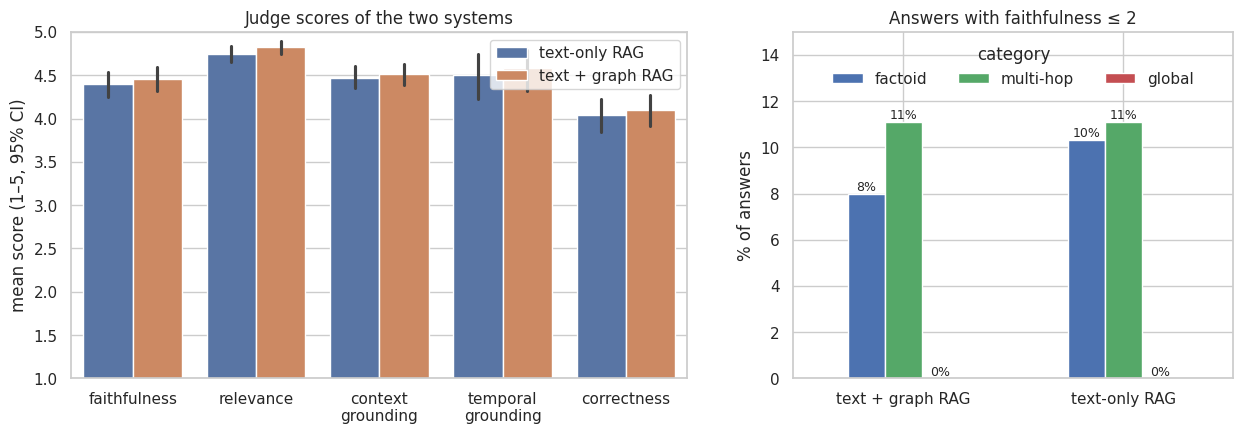

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
long = scores.melt(id_vars=["system"], value_vars=CRITERIA, var_name="criterion", value_name="score").dropna()
long["system"], long["criterion"] = long["system"].map(SYSTEMS), long["criterion"].str.replace("_", "\n")
sns.barplot(data=long, x="criterion", y="score", hue="system", errorbar=("ci", 95), ax=axes[0], palette=["#4C72B0", "#DD8452"])
axes[0].set(ylim=(1, 5), xlabel="", ylabel="mean score (1–5, 95% CI)", title="Judge scores of the two systems")
axes[0].legend(title="")
low = (scores.assign(low=scores["faithfulness"].le(2)).groupby([label(scores), "category"])["low"].mean().unstack()
       .reindex(columns=CATEGORIES) * 100)
low.fillna(0).plot.bar(ax=axes[1], color=["#4C72B0", "#55A868", "#C44E52"], rot=0)
axes[1].set(ylabel="% of answers", xlabel="", title="Answers with faithfulness ≤ 2", ylim=(0, low.max().max() * 1.35))
axes[1].legend(title="category", loc="upper center", ncol=3, frameon=False)
for container in axes[1].containers:                       # a bar at 0 is a result (no such answer), so it is labelled
    axes[1].bar_label(container, fmt="%.0f%%", fontsize=9)
save_fig(fig, "judge_scores_overall")

Both systems score high on the criteria about the answer's form, relevance (4.75–4.82) and faithfulness (4.39–4.46), and lower on correctness (4.04–4.09): an answer is more often loyal to its passages than right, which is what happens when the passages are the wrong ones. Text + graph RAG is ahead on every criterion by 0.04 to 0.08, and the two systems' answers carry the same number of unsupported claims (0.53 and 0.58 per answer; 26% and 27% of answers have at least one). The clearest difference is in the refusals: text-only RAG answers that the sources do not contain the information for 22% of the questions, text + graph RAG for 16%, which is where its higher relevance comes from. Temporal grounding was scored for 150 of 472 answers, those whose question or answer involve a date, at 4.50–4.58: the publication dates in the prompt are used, but not always.

By category, the picture changes. On the factoid questions the graph is 0.05 ahead in correctness (4.16 against 4.11). On the multi-hop questions the two systems are at the same correctness, 3.39, three quarters of a point below the factoid questions, and only faithfulness separates them (4.11 against 4.00). On the 5 global questions the graph is 0.20 ahead (3.60 against 3.40) while the text-only system has the higher context grounding (4.60 against 4.40); with five questions, neither figure means much. By type, the graph helps most on temporal (+0.27) and comparative (+0.13) questions and is behind on analytical ones (4.17 against 4.44, −0.27): a question that asks for a judgement is not answered better by adding two facts to the prompt, and the extra facts may distract from the passage that holds the argument.

### 3.3.1 By question category and type
The three categories of the Q&A session are the main comparison: the graph should matter most for multi-hop questions, whose answer connects entities across articles, and global questions should be the hardest for both systems, since the prompt holds at most 6 passages.

correctness  faithfulness  relevance  \
category  system                                                   
factoid   text + graph RAG         4.16          4.48       4.84   
          text-only RAG            4.11          4.43       4.77   
multi-hop text + graph RAG         3.39          4.11       4.67   
          text-only RAG            3.39          4.00       4.56   
global    text + graph RAG         3.60          4.60       4.60   
          text-only RAG            3.40          4.40       4.40   

                            context_grounding  answers  
category  system                                        
factoid   text + graph RAG               4.54      213  
          text-only RAG                  4.49      213  
multi-hop text + graph RAG               4.28       18  
          text-only RAG                  4.22       18  
global    text + graph RAG               4.40        5  
          text-only RAG                  4.60        5

correctness  faithfulness  temporal_grounding
type        system                                                         
factual     text + graph RAG         3.86          4.34                4.45
            text-only RAG            3.90          4.32                4.77
temporal    text + graph RAG         4.07          4.39                4.44
            text-only RAG            3.80          4.18                4.42
relational  text + graph RAG         4.17          4.55                5.00
            text-only RAG            4.04          4.40                4.50
analytical  text + graph RAG         4.17          4.36                4.71
            text-only RAG            4.44          4.61                4.33
comparative text + graph RAG         4.27          4.66                5.00
            text-only RAG            4.14          4.52                4.67

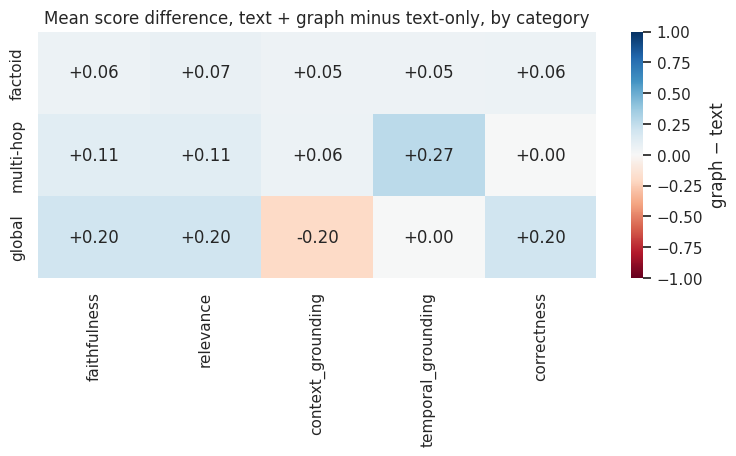

In [14]:
by_cat = (scores.groupby(["category", label(scores)])[["correctness", "faithfulness", "relevance", "context_grounding"]]
          .mean().reindex(CATEGORIES, level=0))
by_cat["answers"] = scores.groupby(["category", label(scores)]).size()
display(by_cat.round(2))

by_type = scores.groupby(["type", label(scores)])[["correctness", "faithfulness", "temporal_grounding"]].mean().reindex(TYPES, level=0)
display(by_type.round(2))

diff = (scores.pivot_table(index="category", columns="system", values=CRITERIA, aggfunc="mean"))
delta = pd.DataFrame({c: diff[(c, "graph")] - diff[(c, "text")] for c in CRITERIA}).reindex(CATEGORIES)
fig, ax = plt.subplots(figsize=(9, 3.2))
sns.heatmap(delta, annot=True, fmt="+.2f", center=0, cmap="RdBu", vmin=-1, vmax=1, cbar_kws={"label": "graph − text"}, ax=ax)
ax.set(title="Mean score difference, text + graph minus text-only, by category", xlabel="", ylabel="")
save_fig(fig, "judge_scores_by_category")

### 3.3.2 Is the difference between the systems reliable?
Both systems answered the same questions, so they are compared **question by question**: for each question, the score of the graph system minus the score of the text-only system. The table gives the mean difference with a 95% bootstrap interval (1,000 resamples of the questions, as in Stage 2), the share of questions where each system is better, and `p`, the share of resamples where the graph system is not better (one-sided). Questions whose prompt the graph did not change get the same answer from both systems (Part 2), so the comparison is also shown on the questions where the prompt changed.

In [15]:
def paired(criterion, mask=None, n=1000):
    wide = scores.pivot(index="id", columns="system", values=criterion).dropna()
    if mask is not None:
        wide = wide[wide.index.isin(mask)]
    if wide.empty:
        return None
    d = (wide["graph"] - wide["text"]).to_numpy()
    idx = np.random.default_rng(SEED).integers(0, len(d), (n, len(d)))
    boots = d[idx].mean(axis=1)
    return {"questions": len(d), "mean difference": d.mean(), "low": np.percentile(boots, 2.5), "high": np.percentile(boots, 97.5),
            "graph better": (d > 0).mean(), "text better": (d < 0).mean(), "same": (d == 0).mean(), "p": (boots <= 0).mean()}

changed = {qid for qid in BY_ID if ("text", qid) in answers and ("graph", qid) in answers
           and ([s["id"] for s in answers[("text", qid)]["result"]["sources"]] != [s["id"] for s in answers[("graph", qid)]["result"]["sources"]]
                or answers[("graph", qid)]["result"]["facts"])}
rows = []
for criterion in ["correctness", "faithfulness", "relevance", "context_grounding"]:
    for subset, mask in [("all questions", None), ("prompt changed by the graph", changed)]:
        for category, cat_mask in [("all", None)] + [(c, {q["id"] for q in EVAL_SET if q["category"] == c}) for c in CATEGORIES]:
            ids = None if mask is None and cat_mask is None else (mask or set(BY_ID)) & (cat_mask or set(BY_ID))
            result = paired(criterion, ids)
            if result:
                rows.append({"criterion": criterion, "subset": subset, "category": category, **result})
paired_table = pd.DataFrame(rows)
paired_table.to_csv(OUT_DIR / "judge_paired.csv", index=False)
display(paired_table[paired_table["category"] == "all"].set_index(["criterion", "subset"]).round(3))
print("Correctness, by category:")
display(paired_table[(paired_table["criterion"] == "correctness") & (paired_table["category"] != "all")]
        .set_index(["subset", "category"]).drop(columns="criterion").round(3))

category  questions  \
criterion         subset                                            
correctness       all questions                    all        236   
                  prompt changed by the graph      all        128   
faithfulness      all questions                    all        236   
                  prompt changed by the graph      all        128   
relevance         all questions                    all        236   
                  prompt changed by the graph      all        128   
context_grounding all questions                    all        236   
                  prompt changed by the graph      all        128   

                                               mean difference    low   high  \
criterion         subset                                                       
correctness       all questions                          0.055 -0.072  0.178   
                  prompt changed by the graph            0.039 -0.180  0.274   
faithfulness      all questions                          0.064 -0.042  0.174   
                  prompt changed by the graph            0.070 -0.109  0.274   
relevance         all questions                          0.076  0.004  0.148   
                  prompt changed by the graph            0.102  0.000  0.227   
context_grounding all questions                          0.042 -0.059  0.153   
                  prompt changed by the graph            0.047 -0.117  0.211   

                                               graph better  text better  \
criterion         subset                                                   
correctness       all questions                       0.153        0.114   
                  prompt changed by the graph         0.180        0.156   
faithfulness      all questions                       0.127        0.114   
                  prompt changed by the graph         0.172        0.180   
relevance         all questions                       0.089        0.051   
                  prompt changed by the graph         0.109        0.062   
context_grounding all questions                       0.161        0.140   
                  prompt changed by the graph         0.203        0.188   

                                                same      p  
criterion         subset                                     
correctness       all questions                0.733  0.217  
                  prompt changed by the graph  0.664  0.383  
faithfulness      all questions                0.758  0.141  
                  prompt changed by the graph  0.648  0.249  
relevance         all questions                0.860  0.019  
                  prompt changed by the graph  0.828  0.035  
context_grounding all questions                0.699  0.217  
                  prompt changed by the graph  0.609  0.288

Correctness, by category:


questions  mean difference    low  \
subset                      category                                       
all questions               factoid          213            0.056 -0.061   
                            multi-hop         18            0.000 -0.833   
                            global             5            0.200 -0.400   
prompt changed by the graph factoid          109            0.037 -0.174   
                            multi-hop         16            0.000 -0.938   
                            global             3            0.333  0.000   

                                        high  graph better  text better  \
subset                      category                                      
all questions               factoid    0.183         0.131        0.103   
                            multi-hop  0.778         0.333        0.222   
                            global     0.800         0.400        0.200   
prompt changed by the graph factoid    0.266         0.156        0.156   
                            multi-hop  0.875         0.312        0.188   
                            global     1.000         0.333        0.000   

                                        same      p  
subset                      category                 
all questions               factoid    0.765  0.186  
                            multi-hop  0.444  0.521  
                            global     0.400  0.347  
prompt changed by the graph factoid    0.688  0.380  
                            multi-hop  0.500  0.495  
                            global     0.667  0.298

The paired comparison confirms the reading above with its uncertainty. Over all 236 questions, the graph is better on relevance by +0.08 with a 95% interval of [+0.00, +0.15] (p = 0.02): the only difference whose interval excludes zero. Correctness (+0.06, [−0.07, +0.18], p = 0.22), faithfulness (+0.06, p = 0.14) and context grounding (+0.04, p = 0.22) all lean the same way and could all be zero. For 73% of the questions the two systems have the same correctness score; the graph is better on 15% and worse on 11%. Restricting the comparison to the 128 questions whose prompt the graph changed does not sharpen it (correctness +0.04, [−0.18, +0.27]): the changed prompts help about as often as they hurt.

By category, the interval for the multi-hop questions is [−0.83, +0.78] around a mean difference of exactly 0.00, with the graph better on 6 questions and worse on 4 out of 18, and the interval for the 5 global questions is [−0.40, +0.80]. The new categories are too small to decide the question they were built to answer, which the limitations state; what they do show is that the graph does not help *by default* on questions that need two articles, since the hoped-for gain would have to be larger than 0.8 to be visible here.

### 3.3.3 What the judge found unsupported
The judge lists the statements an answer makes without support in its evidence. The most frequent kinds, and the answers with the lowest faithfulness, show what the systems get wrong: a date taken from the wrong article, a number attributed to the wrong model, or knowledge added from the model's memory.

In [16]:
def judged(system, qid):
    j, q = judgments[(system, qid)], BY_ID[qid]
    return {"system": SYSTEMS[system], "id": qid, "category": q["category"], "question": q["question"],
            **{c: j["scores"][c] for c in ("faithfulness", "correctness")},
            "unsupported claims": " | ".join(j["unsupported_claims"])[:300],
            "rationale (faithfulness)": j["rationales"]["faithfulness"]}

worst = scores.sort_values(["faithfulness", "correctness"]).head(8)
display(pd.DataFrame([judged(r.system, r.id) for r in worst.itertuples()]).set_index(["system", "id"]))
print(f"Answers with at least one unsupported claim: "
      + ", ".join(f"{SYSTEMS[s]} {v:.0%}" for s, v in scores.assign(any=scores['unsupported_claims'].gt(0)).groupby('system')['any'].mean().items()))
print(f"Judgments flagged for review: {scores['flagged'].sum()} of {len(scores)} ("
      + "; ".join(f"{f}: {n}" for f, n in pd.Series([flag.split(':')[0] for j in judgments.values() for flag in j['review_flags']]).value_counts().items()) + ")")

category  \
system        id              
text-only RAG q003  factoid   
              q096  factoid   
              q097  factoid   
              q101  factoid   
              q138  factoid   
              q146  factoid   
              q248  factoid   
              q295  factoid   

                                                                      question  \
system        id                                                                 
text-only RAG q003                           When did Google launch DataGemma?   
              q096                            Can Gemma 3 run on a single GPU?   
              q097     How much more compute does DeepSeek R1 need than Llama?   
              q101                 Can I run Llama or Mistral on Intel Gaudi2?   
              q138  How much data did Skywork keep to train Skywork-Reward-V2?   
              q146                          Does Grok 2.5 use a shared expert?   
              q248                          How many models are in AuditBench?   
              q295                         When did Meta release Muse Glimmer?   

                    faithfulness  correctness  \
system        id                                
text-only RAG q003             1            1   
              q096             1            1   
              q097             1            1   
              q101             1            1   
              q138             1            1   
              q146             1            1   
              q248             1            1   
              q295             1            1   

                                                                                                                         unsupported claims  \
system        id                                                                                                                              
text-only RAG q003  The provided sources do not specify when Google launched DataGemma. | none state the exact date of the launch. | The...   
              q096  The provided sources do not contain information about whether Gemma 3 can run on a single GPU. | While [S5] states t...   
              q097  The provided sources do not contain information about how much more compute DeepSeek R1 needs compared to Llama. | t...   
              q101  No, you cannot run Llama or Mistral on Intel Gaudi2. | the sources do not specify any direct compatibility or perfor...   
              q138  The provided sources do not specify how much data Skywork kept to train Skywork-Reward-V2. | They mention screening ...   
              q146  The provided sources do not state whether Grok 2.5 uses a shared expert. | While [S3] mentions that Grok 2.5 uses a ...   
              q248  The number of models in AuditBench is four. | The reference to 'four training configurations' and the context of eva...   
              q295  The sources do not mention the release of "Muse Glimmer." | Therefore, based on the provided sources, the release da...   

                                                                                                                   rationale (faithfulness)  
system        id                                                                                                                             
text-only RAG q003  The answer asserts that none of the sources specify the launch date and that the date cannot be determined, but sour...  
              q096  The answer contradicts and ignores a direct statement in S5 that explicitly says Gemma 3 is designed to run on a sin...  
              q097  Most statements in the answer contradict or ignore explicit information in the provided sources (notably [S4] which ...  
              q101  The answer starts by denying you can run Llama or Mistral on Gaudi2, which directly contradicts S1 that explicitly l...  
              q138  The answer claims the sources do not specify how much data was kept, but S1 and S2 explicitly

Answers with at least one unsupported claim: text + graph RAG 26%, text-only RAG 27%
Judgments flagged for review: 2 of 472 (faithfulness: 3)


The worst-judged answers are of one kind: the model contradicts a passage it was given. All eight answers with faithfulness 1 and correctness 1 are text-only answers to factoid questions, and in each the judge's rationale points to the passage in the prompt that states the fact. Six of them are refusals, the model saying the sources do not contain the information when they do (the launch date of DataGemma, whether Gemma 3 runs on one GPU, the release of Muse Glimmer); the other two assert the opposite of the source (that Llama cannot run on Intel Gaudi2, that AuditBench has four models). The judge lists the refusal or the wrong statement itself as the unsupported claim. This is the generation failure of Section 3.5, as opposed to the retrieval failure: the right chunk is there and the 4B model does not find the fact in it, usually when the fact is a number or a date in a long passage. The share of answers with at least one unsupported claim is the same for both systems (26% and 27%), so the graph facts in the prompt neither add unsupported statements nor remove them. The judge flagged 2 of 472 judgments for review, both on faithfulness, where its own rationale and score disagreed.

## 3.4 Does the Judge Agree with a Person?
A judge is a model too. Before the scores above are used to compare systems, a sample of them is checked by hand: 15 questions (9 factoid, 4 multi-hop, 2 global, drawn with a fixed seed) with the answers of both systems, 30 answers in all. The sheet shows the question, the reference answer, the evidence the system saw and the answer, **without the system's name and without the judge's scores**, and the reviewer gives the same 1–5 scores for faithfulness, relevance and correctness, following the criteria of Section 3.3. The agreement with the judge is then measured: exact agreement, agreement within one point, and the Spearman correlation per criterion.

In [17]:
CHECK_SHEET, CHECK_KEY = OUT_DIR / "judge_check_sheet.xlsx", OUT_DIR / "judge_check_key.csv"
HUMAN_CRITERIA = ["faithfulness", "relevance", "correctness"]

def reviewed_sheet():
    # The reviewed sheet: judge_check_reviewed.xlsx, or the blind sheet itself if the scores were filled in place
    for path in (wp3_file("judge_check_reviewed.xlsx"), CHECK_SHEET):
        if path.exists():
            try:
                filled = pd.read_excel(path, sheet_name="check")[HUMAN_CRITERIA].notna().all(axis=1).sum()
            except Exception:
                continue
            if filled:
                return path, int(filled)
    return None, 0

def evidence_text(result, limit=1500):
    blocks = []
    for s in result["sources"]:
        text = CHUNK[s["id"]]["text"] if s["id"] in CHUNK else ""
        blocks.append(f"[{s['label']}] {s['title']} · {s['date']}\n{text[:limit]}{' …' if len(text) > limit else ''}")
    for f in result["facts"]:
        blocks.append(f"[{f['label']}] graph fact: {f['subject']} {f['relation']} {f['object']} ({f.get('date', '')})")
    return "\n\n".join(blocks)

# The sample is drawn again if it was drawn from another test set (a question it holds is no longer in it)
if CHECK_KEY.exists() and not set(pd.read_csv(CHECK_KEY)["question_id"]) <= set(BY_ID):
    print(f"{CHECK_SHEET.name} was built from a different test set: it is built again")
    CHECK_KEY.unlink()

if not CHECK_KEY.exists():
    rng = np.random.default_rng(SEED)
    sample = []
    for category, n in [("factoid", 9), ("multi-hop", 4), ("global", 2)]:
        pool = [q for q in EVAL_SET if q["category"] == category and ("text", q["id"]) in judgments]
        sample += list(rng.choice(pool, size=min(n, len(pool)), replace=False)) if pool else []
    rows = [(q, system) for q in sample for system in SYSTEMS if (system, q["id"]) in judgments]
    rng.shuffle(rows)
    sheet = pd.DataFrame([{"row": n, "question_id": q["id"], "category": q["category"], "question": q["question"],
                           "reference_answer": q["reference_answer"],
                           "evidence": evidence_text(answers[(system, q["id"])]["result"]),
                           "answer": answers[(system, q["id"])]["result"]["answer"],
                           **{c: "" for c in HUMAN_CRITERIA}, "note": "", "reviewer": ""}
                          for n, (q, system) in enumerate(rows, start=1)])
    pd.DataFrame({"row": sheet["row"], "question_id": sheet["question_id"], "system": [s for _, s in rows]}).to_csv(CHECK_KEY, index=False)
    with pd.ExcelWriter(CHECK_SHEET) as writer:
        pd.DataFrame({"HOW TO SCORE": [
            "For every row: read the question, the reference answer, the evidence (the passages and graph facts the system saw) and the answer.",
            "Give an integer score from 1 to 5 for each criterion, judging only by the criterion:",
            "faithfulness: every statement in the answer is supported by the evidence (5: all supported; 3: some unsupported; 1: most unsupported or contradicted).",
            "relevance: the answer addresses the question directly and completely (5: fully; 3: partly or drifts; 1: does not answer).",
            "correctness: the answer agrees with the reference answer on the facts that matter (5: all key facts; 3: misses or blurs some; 1: contradicts or misses).",
            "An answer that says the sources do not contain the information is faithful (5) but not correct if the reference answer exists in the corpus.",
            "Do not look at the notebook's judge scores before scoring; the system that wrote each answer is hidden on purpose."]}).to_excel(writer, sheet_name="INSTRUCTIONS", index=False)
        sheet.to_excel(writer, sheet_name="check", index=False)
    print(f"Check sheet written: {CHECK_SHEET.name} ({len(sheet)} answers)")

key = pd.read_csv(CHECK_KEY)
CHECK_REVIEWED, n_filled = reviewed_sheet()
if CHECK_REVIEWED is not None:
    print(f"Reviewed sheet: {CHECK_REVIEWED} ({n_filled} answers scored)")
    human = pd.read_excel(CHECK_REVIEWED, sheet_name="check").merge(key, on=["row", "question_id"])
    human = human[human[HUMAN_CRITERIA].notna().all(axis=1)]
    human[HUMAN_CRITERIA] = human[HUMAN_CRITERIA].astype(int)
    rows = []
    for c in HUMAN_CRITERIA:
        pairs = human.apply(lambda r: (r[c], judgments[(r["system"], r["question_id"])]["scores"][c]), axis=1)
        h, m = np.array([p[0] for p in pairs]), np.array([p[1] for p in pairs], dtype=float)
        ok = ~np.isnan(m)
        rows.append({"criterion": c, "answers": int(ok.sum()), "human mean": h[ok].mean(), "judge mean": m[ok].mean(),
                     "exact agreement": (h[ok] == m[ok]).mean(), "within 1 point": (np.abs(h[ok] - m[ok]) <= 1).mean(),
                     "spearman": pd.Series(h[ok]).corr(pd.Series(m[ok]), method="spearman"),
                     "judge higher": (m[ok] > h[ok]).mean(), "human higher": (h[ok] > m[ok]).mean()})
    agreement = pd.DataFrame(rows).set_index("criterion")
    agreement.to_csv(OUT_DIR / "judge_agreement.csv")
    display(agreement.round(2))
    human["system"] = human["system"].map(SYSTEMS)
    display(human.groupby("system")[HUMAN_CRITERIA].mean().round(2).rename(columns=lambda c: f"human {c}"))
else:
    print(f"Reviewed sheet not found: fill in {CHECK_SHEET.name} (in {OUT_DIR}) and save it there, as judge_check_reviewed.xlsx or in place")

Reviewed sheet: /content/drive/MyDrive/HSLU/CLT/extraction_outputs/stage3/wp3/judge_check_sheet.xlsx (30 answers scored)


,answers,human mean,judge mean,exact agreement,within 1 point,spearman,judge higher,human higher
criterion,,,,,,,,
faithfulness,30,4.5,4.63,0.83,0.97,0.82,0.13,0.03
relevance,30,4.4,4.80,0.50,0.97,0.48,0.43,0.07
correctness,30,4.0,4.43,0.60,0.90,0.79,0.37,0.03


,human faithfulness,human relevance,human correctness
system,,,
text + graph RAG,4.47,4.4,4.0
text-only RAG,4.53,4.4,4.0


### 3.4.1 Does the Judge Agree with a More Careful Version of Itself?
The judge of Section 3.3 runs with its reasoning effort set to **low**, which is what makes 472 judgments affordable in time and in cost. Whether that setting is enough is a question about the measurement, not about the systems, so it is tested: the same answers as the sheet above are judged a second time with the effort set to **high**, and the two settings are compared as the reviewer and the judge are compared.

Two outcomes are informative. If the scores move little, the low setting is reading the answers rather than guessing, and the cheaper setting is justified. If they move but move *in the same direction for both systems*, the comparison of Section 3.3.2 is still sound, because it is paired: a bias shared by both systems cancels in the difference. Only a shift that favours one system would change the conclusions, and that is what the last line below measures.

In [18]:
JUDGMENTS_HIGH = OUT_DIR / "judgments_high.jsonl"
high = {}
if JUDGMENTS_HIGH.exists():
    for line in JUDGMENTS_HIGH.read_text(encoding="utf-8").splitlines():
        record = json.loads(line)
        if (record["system"], record["id"]) in judgments:
            high[(record["system"], record["id"])] = record

sample_keys = [(r["system"], r["question_id"]) for _, r in key.iterrows() if (r["system"], r["question_id"]) in judgments]
todo = [k for k in sample_keys if k not in high]
if todo and OPENAI_API_KEY:
    use_judge(effort="high")
    started = time.perf_counter()
    with JUDGMENTS_HIGH.open("a", encoding="utf-8") as handle:
        for system, qid in todo:
            record = judge_one(system, qid, effort="high")
            high[(system, qid)] = record
            handle.write(json.dumps(record, ensure_ascii=False) + "\n")
            handle.flush()
    use_judge()                                           # back to the setting of Section 3.3
    print(f"{len(todo)} answers judged again at high effort in {time.perf_counter() - started:.0f} s")

if high:
    pairs = pd.DataFrame([{"system": s, "id": q, "criterion": c,
                           "low": judgments[(s, q)]["scores"][c], "high": high[(s, q)]["scores"][c]}
                          for (s, q) in high for c in CRITERIA
                          if judgments[(s, q)]["scores"].get(c) is not None and high[(s, q)]["scores"].get(c) is not None])
    effort = pairs.groupby("criterion").apply(lambda d: pd.Series({
        "answers": len(d), "low effort": d["low"].mean(), "high effort": d["high"].mean(),
        "mean difference": (d["high"] - d["low"]).mean(), "exact agreement": (d["high"] == d["low"]).mean(),
        "within 1 point": ((d["high"] - d["low"]).abs() <= 1).mean(),
        "spearman": d["low"].corr(d["high"], method="spearman")}), include_groups=False).reindex(CRITERIA).dropna(how="all")
    effort.to_csv(OUT_DIR / "judge_effort.csv")
    display(effort.round(2))
    # Does the higher effort move the two systems differently? That, and only that, would change Section 3.3.2
    shift = pairs.assign(d=pairs["high"] - pairs["low"]).groupby([pairs["system"].map(SYSTEMS), "criterion"])["d"].mean().unstack()
    display(shift.reindex(columns=CRITERIA).dropna(axis=1, how="all").round(2))
    per_system = pairs.groupby(["criterion", "system"]).size().unstack()
    enough = per_system.index[(per_system >= 10).all(axis=1)]                # a shift on fewer answers is noise
    gaps = shift.diff().iloc[-1].abs().reindex(enough).dropna()
    print("Difference between the two systems' shifts, per criterion (10 or more answers per system):",
          ", ".join(f"{c} {g:.2f}" for c, g in gaps.items()),
          "| compare with the system differences of Section 3.3.2, 0.04 to 0.08")

,answers,low effort,high effort,mean difference,exact agreement,within 1 point,spearman
criterion,,,,,,,
faithfulness,30.0,4.63,4.80,0.17,0.70,0.93,0.35
relevance,30.0,4.80,4.73,-0.07,0.93,1.00,1.00
context_grounding,30.0,4.77,4.87,0.10,0.77,0.93,0.15
temporal_grounding,10.0,4.80,4.50,-0.30,0.80,0.90,0.57
correctness,30.0,4.43,4.23,-0.20,0.70,0.83,0.67


criterion,faithfulness,relevance,context_grounding,temporal_grounding,correctness
system,,,,,
text + graph RAG,-0.07,-0.07,-0.13,-0.6,-0.2
text-only RAG,0.40,-0.07,0.33,0.0,-0.2


Difference between the two systems' shifts, per criterion (10 or more answers per system): context_grounding 0.47, correctness 0.00, faithfulness 0.47, relevance 0.00 | compare with the system differences of Section 3.3.2, 0.04 to 0.08


The high-effort judge agrees with the low-effort one within one point on 83–100% of the answers and exactly on 70–93%, and moves the means by 0.07 to 0.20: it is slightly stricter on correctness (4.43 → 4.23) and slightly more lenient on faithfulness (4.63 → 4.80). The Spearman correlations are high where the scores vary (relevance 1.00, correctness 0.67) and low where they hardly do (context grounding 0.15: nearly every answer scores 5 under both settings, so the few that differ decide the coefficient). Five of the 30 correctness scores moved by two points or more, which is the size of disagreement the human check of Section 3.4 measures on the same answers.

The test that matters for the conclusions is the last line: on **correctness** and **relevance**, the two criteria the comparison of Section 3.3.2 rests on, the higher effort shifts both systems by the same amount (−0.20 and −0.20, −0.07 and −0.07), so the differences between them would be unchanged by the more careful judge. On faithfulness and context grounding the shifts differ: the high-effort judge raises the text-only answers by 0.33–0.40 and leaves the graph answers where they were, on 15 answers per system. That is enough to reverse the sign of the two smallest system differences of Section 3.3.2 (+0.06 and +0.04, neither significant), which should therefore be read as *no difference*, not as a small advantage of the graph. The temporal shift (−0.6 for the graph system) rests on five answers and is not interpreted.

The cost settles the choice of setting: the high-effort judgments took 50 s per answer against 7 s at low effort, so judging the 708 answers of this part would take about ten hours instead of one and a half. The low setting is adequate for a paired comparison, and the sample shows where it is not: for the absolute level of faithfulness, which the judge reads differently when it reads longer.

The reviewer and the judge agree within one point on 90–97% of the 30 answers and exactly on 83% for faithfulness, 60% for correctness and 50% for relevance. The rank correlations are 0.82 for faithfulness and 0.79 for correctness, 0.48 for relevance; the judge gives relevance 5 to almost every answer that addresses the question, the reviewer distinguishes a complete answer from a partial one. The disagreements have one direction: the judge is more lenient. It scores higher than the reviewer on 13% of the answers for faithfulness, 37% for correctness and 43% for relevance, and lower on 3–7%, so the means of Section 3.3 are about 0.1 (faithfulness) to 0.4 points (relevance, correctness) above what a person gives the same answers. The absolute levels in this part are therefore optimistic by that much; the ranking of the answers, which the paired comparisons use, is the same for the two criteria that matter most.

The reviewer, who did not know which system had written each answer, gave the two systems the same scores: correctness 4.0 and 4.0, relevance 4.4 and 4.4, faithfulness 4.47 and 4.53. On this sample a person sees no difference between text-only and text + graph RAG, which is consistent with the paired result of Section 3.3.2 on all 236 questions, where the differences are within 0.08 and only one of them is distinguishable from zero. Taken with Section 3.4.1, the picture of the judge is that of a lenient but consistent reader: lenient against a person, stable against a more careful version of itself on the criteria that decide the comparison.

## 3.5 Retrieval Diagnosis: Where Do the Answers Fail?
An answer can only be right if the right article reaches the prompt. Part 2 measured retrieval on the Part 1 questions; here the measure is repeated on the full test set with the text-only search of Part 1, per category: hit@k (a source article is among the first k articles) and, since the new questions have several source articles, recall@10 (the share of the source articles among the first 10). The judge's correctness score is then split by whether the source article was in the prompt, which separates retrieval failures from generation failures.

In [19]:
RETRIEVAL_CACHE = OUT_DIR / "retrieval"
RETRIEVAL_CACHE.mkdir(exist_ok=True)

def evaluate_retrieval(name, retrieve_fn, questions=EVAL_SET):
    # Retrieval metrics of `retrieve_fn(q)` over `questions`, per question and in summary.
    # Saved on Drive and read back when it holds exactly these questions, so re-runs do not search again.
    cached = RETRIEVAL_CACHE / f"{re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_')}.csv"
    if cached.exists():
        per = pd.read_csv(cached)
        if set(per["id"]) == {q["id"] for q in questions}:
            print(f"{name}: hit@1 {per['hit@1'].mean():.3f} · hit@10 {per['hit@10'].mean():.3f} "
                  f"· recall@10 {per['recall@10'].mean():.3f} · MRR {per['reciprocal_rank'].mean():.3f} (from the cache)")
            return per
    started = time.perf_counter()
    results = [{"question": q["question"], "relevant": q["source_ids"], "retrieved": retrieve_fn(q)} for q in questions]
    m = retrieval_metrics.run({"results": results, "k": [1, 3, 5, 10]}, context=ctx)
    per = pd.DataFrame(m["per_question"]).assign(id=[q["id"] for q in questions], category=[q["category"] for q in questions],
                                                 type=[q["type"] for q in questions], configuration=name)
    print(f"{name}: hit@1 {m['summary']['hit@1']:.3f} · hit@10 {m['summary']['hit@10']:.3f} · recall@10 {m['summary']['recall@10']:.3f} "
          f"· MRR {m['summary']['mrr']:.3f} ({time.perf_counter() - started:.0f} s)")
    per.to_csv(cached, index=False)
    return per

RETRIEVAL = {}
for strategy in ["sparse", "dense", "hybrid"]:
    RETRIEVAL[strategy] = evaluate_retrieval(strategy, lambda q, s=strategy: search(q["question"], strategy=s))
baseline_retrieval = RETRIEVAL["hybrid"]
print("\nHybrid search of Part 1, by category:")
display(baseline_retrieval.groupby("category")[["hit@1", "hit@5", "hit@10", "recall@10", "reciprocal_rank"]].mean()
        .reindex(CATEGORIES).rename(columns={"reciprocal_rank": "MRR"}).round(3))

sparse: hit@1 0.640 · hit@10 0.890 · recall@10 0.867 · MRR 0.728 (from the cache)
dense: hit@1 0.436 · hit@10 0.758 · recall@10 0.732 · MRR 0.543 (from the cache)
hybrid: hit@1 0.551 · hit@10 0.864 · recall@10 0.843 · MRR 0.666 (from the cache)

Hybrid search of Part 1, by category:


,hit@1,hit@5,hit@10,recall@10,MRR
category,,,,,
factoid,0.577,0.836,0.878,0.878,0.685
multi-hop,0.333,0.778,0.778,0.620,0.522
global,0.200,0.600,0.600,0.140,0.350


In [20]:
# Retrieval of the graph system on the Part 1 questions (reciprocal ranks saved by Part 2)
wp2_retrieval = pd.read_csv(WP2_ART / "retrieval_results.csv")
print("Part 1 questions, MRR by type (Part 2 measurement):")
display(wp2_retrieval.groupby("type")[["rr_text", "rr_text_graph"]].mean().reindex(TYPES)
        .rename(columns={"rr_text": "text-only", "rr_text_graph": "text + graph"}).T.round(3))

# Correctness when the source article is in the prompt and when it is not
in_prompt = scores.groupby([label(scores), "source_in_prompt"]).agg(answers=("id", "size"), correctness=("correctness", "mean"),
                                                                    faithfulness=("faithfulness", "mean"), no_answer=("no_answer", "mean"))
display(in_prompt.round(2))
print("New questions: share of answers whose prompt holds ALL the source articles:")
display(scores[scores["category"] != "factoid"].groupby([label(scores), "category"])["all_sources_in_prompt"].mean().unstack().round(2))

Part 1 questions, MRR by type (Part 2 measurement):


type,factual,temporal,relational,analytical,comparative
text-only,0.778,0.543,0.665,0.740,0.676
text + graph,0.781,0.581,0.721,0.749,0.707


answers  correctness  faithfulness  \
system           source_in_prompt                                       
text + graph RAG False                  42         3.38          4.31   
                 True                  194         4.25          4.49   
text-only RAG    False                  44         3.30          4.27   
                 True                  192         4.21          4.42   

                                   no_answer  
system           source_in_prompt             
text + graph RAG False                  0.24  
                 True                   0.14  
text-only RAG    False                  0.36  
                 True                   0.18

New questions: share of answers whose prompt holds ALL the source articles:


category,global,multi-hop
system,,
text + graph RAG,0.0,0.28
text-only RAG,0.0,0.28


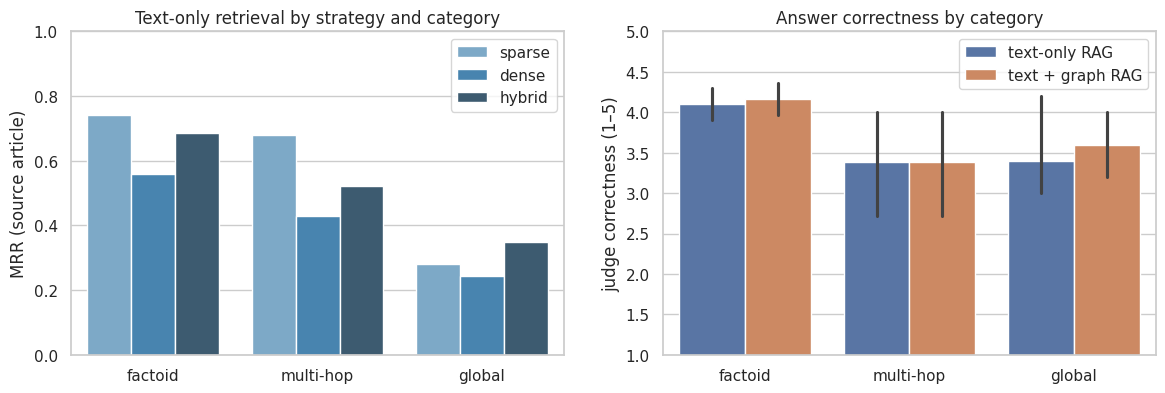

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
r = pd.concat(RETRIEVAL.values())
sns.barplot(data=r, x="category", y="reciprocal_rank", hue="configuration", order=CATEGORIES, ax=axes[0], palette="Blues_d", errorbar=None)
axes[0].set(ylim=(0, 1), xlabel="", ylabel="MRR (source article)", title="Text-only retrieval by strategy and category")
sns.barplot(data=scores.assign(system=label(scores)), x="category", y="correctness", hue="system", order=CATEGORIES, ax=axes[1],
            palette=["#4C72B0", "#DD8452"], errorbar=("ci", 95))
axes[1].set(ylim=(1, 5), xlabel="", ylabel="judge correctness (1–5)", title="Answer correctness by category")
for ax in axes:
    ax.legend(title="")
save_fig(fig, "retrieval_and_correctness")

Retrieval explains most of the correctness scores. When a source article is in the prompt (81–82% of the answers), correctness is 4.21–4.25; when it is not, 3.30–3.38, and the model refuses twice as often (text-only: 36% against 18%). The two systems put a source article in the prompt equally often (192 and 194 of 236 answers), which is why their scores are so close: the graph's entity route reorders the candidates but rarely brings in an article the hybrid search had missed.

By category, hybrid search finds a source article at rank 1 for 58% of the factoid questions, 33% of the multi-hop and 20% of the global ones (MRR 0.69, 0.52, 0.35), and the recall of all the source articles in the first ten is 0.88, 0.62 and 0.14. For the global questions, 86% of the articles needed are missing from the first ten results, and no answer to a global question, from either system, had all its source articles in the prompt (28% for the multi-hop questions). The cause is the ranking, not the size of the prompt: the prompt holds 6 passages with at most 2 per article, so it could hold the five articles of a global question, but they are not among the candidates to begin with. A question that names several models is matched to the chunks about the better-known of them, and the others fall below the first ten.

Among the three strategies, sparse search is the best on this test set (MRR 0.73, hit@1 0.64), hybrid second (0.67, 0.55) and dense last (0.54, 0.44). Part 1 chose hybrid on five example questions; on 236 the word-based search wins, and Section 3.1.1 says why: the questions share words with their passages, so a word match is a strong signal here and the dense half of the hybrid score dilutes it. The measurement of Part 2 on its own test set points the same way as Section 3.3: the graph raises the MRR of the source article for every type, most for temporal (0.54 → 0.58) and relational (0.67 → 0.72) questions, by small amounts.

## 3.6 Enhancement: Re-ranking the Retrieved Passages
**Limitation addressed.** Section 3.5 locates the main failure in retrieval: when the source article reaches the prompt, both systems answer correctly (4.2), and when it does not, they do not (3.3). Hybrid search puts a source article first for 55% of the questions and the dense half of its score is the weaker one (dense alone: hit@1 0.44). The passages that reach the model are the first 6 of a ranking that scores each chunk against the question through two compressed representations, an embedding and a bag of words, and that ranking mixes up close names (*Gemma 3* and *Gemma 4*, *Nemotron Nano* and *Nemotron 3 Nano*) and favours the better-known of two entities in a question. Adding the knowledge graph did not fix this: it changed the prompt of 128 questions and improved correctness on 23 of them while worsening 20.

**Enhancement.** The text-only pipeline retrieves 30 chunks by hybrid search and gives the first 6 (2 per article) to the language model. Hybrid search ranks the chunks by their embedding and their words, two compressed views of a chunk: close names (*Gemma 3* vs *Gemma 4*, *Nemotron Nano* vs *Nemotron 3 Nano*) and questions that name two entities are where this ranking fails. A **cross-encoder re-ranker** reads the question together with the full text of every candidate chunk and scores their relevance jointly (the attention of a transformer over the pair, slide 5.1); it is slower, so it runs on a candidate set from retrieval, not on the whole corpus (*embeddings for recall, re-ranking for precision*, course skeleton A3.5). The enhanced pipeline retrieves **60** chunks by hybrid search, re-ranks them with `cross-encoder/ms-marco-MiniLM-L-6-v2` (the re-ranker shipped with the toolbox), keeps the first 30 and gives the first 6 to the same prompt and model. Everything else is unchanged, so the difference comes from the order of the passages.

The enhancement is evaluated in two steps: on retrieval, for every question and against two other candidates (re-ranking the 30 baseline chunks only, and a recency boost for recent news), and end to end, with the same judge, on the answers it produces.

In [22]:
def search_and_rerank(question, size=60, keep=30):
    # Hybrid search of `size` chunks, re-ranked by the cross-encoder; the first `keep` are kept
    return rerank.run({"input": search(question, size=size), "keep": keep}, context=ctx)

VARIANTS = {
    "hybrid 30 (Part 1)": lambda q: search(q["question"]),
    "hybrid 60": lambda q: search(q["question"], size=60),
    "hybrid 30 + re-ranking": lambda q: search_and_rerank(q["question"], size=30),
    "hybrid 60 + re-ranking": lambda q: search_and_rerank(q["question"], size=60),
    "hybrid 30 + recency (half-life 1 year)": lambda q: search(q["question"], recency_half_life_days=365),
}
for name, fn in VARIANTS.items():
    if name not in RETRIEVAL:
        RETRIEVAL[name] = evaluate_retrieval(name, fn)
variants = pd.concat([RETRIEVAL[n] for n in VARIANTS])
summary = variants.groupby("configuration")[["hit@1", "hit@3", "hit@5", "hit@10", "recall@10", "reciprocal_rank"]].mean().reindex(list(VARIANTS))
summary.rename(columns={"reciprocal_rank": "MRR"}).round(3).to_csv(OUT_DIR / "retrieval_variants.csv")
display(summary.rename(columns={"reciprocal_rank": "MRR"}).round(3))
print("MRR by category:")
display(variants.groupby(["configuration", "category"])["reciprocal_rank"].mean().unstack().reindex(list(VARIANTS))[CATEGORIES].round(3))
print("MRR by type:")
display(variants.groupby(["configuration", "type"])["reciprocal_rank"].mean().unstack().reindex(list(VARIANTS))[TYPES].round(3))

hybrid 30 (Part 1): hit@1 0.551 · hit@10 0.864 · recall@10 0.843 · MRR 0.666 (from the cache)
hybrid 60: hit@1 0.551 · hit@10 0.864 · recall@10 0.845 · MRR 0.667 (from the cache)
hybrid 30 + re-ranking: hit@1 0.648 · hit@10 0.907 · recall@10 0.888 · MRR 0.735 (from the cache)
hybrid 60 + re-ranking: hit@1 0.644 · hit@10 0.907 · recall@10 0.879 · MRR 0.731 (from the cache)
hybrid 30 + recency (half-life 1 year): hit@1 0.250 · hit@10 0.602 · recall@10 0.582 · MRR 0.357 (from the cache)


,hit@1,hit@3,hit@5,hit@10,recall@10,MRR
configuration,,,,,,
hybrid 30 (Part 1),0.551,0.767,0.826,0.864,0.843,0.666
hybrid 60,0.551,0.767,0.826,0.864,0.845,0.667
hybrid 30 + re-ranking,0.648,0.801,0.839,0.907,0.888,0.735
hybrid 60 + re-ranking,0.644,0.797,0.835,0.907,0.879,0.731
hybrid 30 + recency (half-life 1 year),0.250,0.386,0.487,0.602,0.582,0.357


MRR by category:


category,factoid,multi-hop,global
configuration,,,
hybrid 30 (Part 1),0.685,0.522,0.350
hybrid 60,0.686,0.526,0.354
hybrid 30 + re-ranking,0.757,0.584,0.345
hybrid 60 + re-ranking,0.753,0.573,0.349
hybrid 30 + recency (half-life 1 year),0.358,0.429,0.071


MRR by type:


type,factual,temporal,relational,analytical,comparative
configuration,,,,,
hybrid 30 (Part 1),0.756,0.538,0.658,0.693,0.660
hybrid 60,0.757,0.540,0.658,0.694,0.661
hybrid 30 + re-ranking,0.774,0.633,0.739,0.737,0.781
hybrid 60 + re-ranking,0.773,0.636,0.733,0.734,0.763
hybrid 30 + recency (half-life 1 year),0.332,0.329,0.376,0.390,0.369


hybrid 60 + re-ranking vs Part 1: mean reciprocal-rank difference +0.065 [+0.024, +0.109], better for 28% of the questions, worse for 18%, p = 0.002


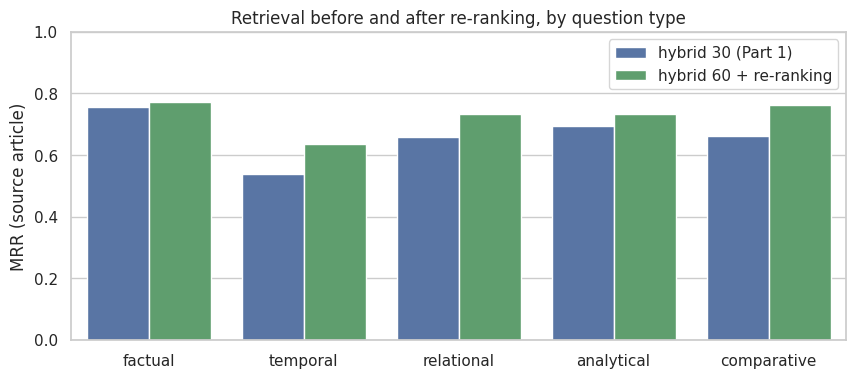

In [23]:
# Paired comparison of the reciprocal ranks: enhanced vs Part 1, per question
ENHANCED = "hybrid 60 + re-ranking"
rr = variants.pivot(index="id", columns="configuration", values="reciprocal_rank")
d = rr[ENHANCED] - rr["hybrid 30 (Part 1)"]
boots = d.to_numpy()[np.random.default_rng(SEED).integers(0, len(d), (1000, len(d)))].mean(axis=1)
print(f"{ENHANCED} vs Part 1: mean reciprocal-rank difference {d.mean():+.3f} "
      f"[{np.percentile(boots, 2.5):+.3f}, {np.percentile(boots, 97.5):+.3f}], better for {(d > 0).mean():.0%} of the questions, "
      f"worse for {(d < 0).mean():.0%}, p = {(boots <= 0).mean():.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
plot = variants[variants["configuration"].isin(["hybrid 30 (Part 1)", ENHANCED])]
sns.barplot(data=plot, x="type", y="reciprocal_rank", hue="configuration", order=TYPES, ax=ax, palette=["#4C72B0", "#55A868"], errorbar=None)
ax.set(ylim=(0, 1), xlabel="", ylabel="MRR (source article)", title="Retrieval before and after re-ranking, by question type")
ax.legend(title="")
save_fig(fig, "enhancement_retrieval")

Re-ranking improves retrieval on every summary measure: hit@1 from 0.55 to 0.64, hit@10 from 0.86 to 0.91, MRR from 0.67 to 0.73, a paired difference of +0.065 in reciprocal rank with a 95% interval of [+0.02, +0.11] (p = 0.002), better for 28% of the questions and worse for 18%. Two of the other variants show where the gain comes from. Retrieving 60 candidates instead of 30 changes nothing on its own (MRR 0.667 against 0.666), and re-ranking 30 candidates is as good as re-ranking 60 (0.735 against 0.731): the improvement is the re-ranker reading question and passage together, not the larger pool, so the cheaper configuration would do. The recency boost, the natural idea for a news corpus, is harmful (MRR 0.36): the test questions are about events spread over two years, and favouring recent articles pushes the 2024 and 2025 sources down for no reason.

By type, re-ranking helps most on the temporal (0.54 → 0.64) and comparative (0.66 → 0.76) questions, the two types where a question names two things, a model and a date or two models, and a cross-encoder can weigh both. By category, it helps the factoid (0.69 → 0.75) and multi-hop (0.52 → 0.57) questions and not the global ones (0.35 → 0.35): a re-ranker scores one passage at a time and cannot know that a question needs several different articles.

### 3.6.1 End-to-end: answers with the re-ranked passages
The enhanced system answers every question with the re-ranked passages and the unchanged prompt and model, and the judge scores the answers as in Section 3.3. The comparison with the text-only baseline is paired, question by question; the prompt is identical for the questions whose first 6 passages did not change, so those answers are expected to be the same.

In [24]:
SYSTEMS_ALL = {**SYSTEMS, "text+rerank": "text-only RAG + re-ranking"}
SYSTEM_NAMES.update(SYSTEMS_ALL)
generate_all("text+rerank", EVAL_SET, lambda q: {"input": search_and_rerank(q["question"])})
judge_all({"text+rerank"})
scores = score_table(SYSTEMS_ALL)
scores.to_csv(OUT_DIR / "judge_scores.csv", index=False)
label = lambda df: df["system"].map(SYSTEMS_ALL)
HAS_ENHANCED = any(system == "text+rerank" for system, _ in judgments)
assert HAS_ENHANCED, "no judged answers of the enhanced system yet: run the generation (Colab GPU) and the judge first"

same_prompt = {qid for qid in BY_ID if ("text", qid) in answers and ("text+rerank", qid) in answers
               and [s["id"] for s in answers[("text", qid)]["result"]["sources"]] == [s["id"] for s in answers[("text+rerank", qid)]["result"]["sources"]]}
print(f"Prompt unchanged by re-ranking for {len(same_prompt)} of {sum(('text+rerank', q['id']) in answers for q in EVAL_SET)} questions")

display(scores.groupby(label(scores)).agg(answers=("id", "size"), **{c: (c, "mean") for c in CRITERIA}, no_answer=("no_answer", "mean"),
                                           source_in_prompt=("source_in_prompt", "mean")).round(2))
display(scores.groupby(["category", label(scores)])[["correctness", "faithfulness", "source_in_prompt"]].mean().reindex(CATEGORIES, level=0).round(2))

Prompt unchanged by re-ranking for 0 of 236 questions


,answers,faithfulness,relevance,context_grounding,temporal_grounding,correctness,no_answer,source_in_prompt
system,,,,,,,,
text + graph RAG,236,4.46,4.82,4.51,4.58,4.09,0.16,0.82
text-only RAG,236,4.39,4.75,4.47,4.50,4.04,0.22,0.81
text-only RAG + re-ranking,236,4.51,4.77,4.56,4.64,4.25,0.15,0.83


correctness  faithfulness  \
category  system                                                  
factoid   text + graph RAG                   4.16          4.48   
          text-only RAG                      4.11          4.43   
          text-only RAG + re-ranking         4.37          4.55   
multi-hop text + graph RAG                   3.39          4.11   
          text-only RAG                      3.39          4.00   
          text-only RAG + re-ranking         3.33          4.11   
global    text + graph RAG                   3.60          4.60   
          text-only RAG                      3.40          4.40   
          text-only RAG + re-ranking         2.60          4.00   

                                      source_in_prompt  
category  system                                        
factoid   text + graph RAG                        0.83  
          text-only RAG                           0.82  
          text-only RAG + re-ranking              0.86  
multi-hop text + graph RAG                        0.78  
          text-only RAG                           0.78  
          text-only RAG + re-ranking              0.61  
global    text + graph RAG                        0.60  
          text-only RAG                           0.60  
          text-only RAG + re-ranking              0.60

questions  \
comparison                 criterion         subset                                    
re-ranking vs text-only    correctness       all questions                       236   
                                             prompt changed by re-ranking        236   
re-ranking vs text + graph correctness       all questions                       236   
re-ranking vs text-only    faithfulness      all questions                       236   
                                             prompt changed by re-ranking        236   
re-ranking vs text + graph faithfulness      all questions                       236   
re-ranking vs text-only    relevance         all questions                       236   
                                             prompt changed by re-ranking        236   
re-ranking vs text + graph relevance         all questions                       236   
re-ranking vs text-only    context_grounding all questions                       236   
                                             prompt changed by re-ranking        236   
re-ranking vs text + graph context_grounding all questions                       236   

                                                                           mean difference  \
comparison                 criterion         subset                                          
re-ranking vs text-only    correctness       all questions                           0.216   
                                             prompt changed by re-ranking            0.216   
re-ranking vs text + graph correctness       all questions                           0.161   
re-ranking vs text-only    faithfulness      all questions                           0.114   
                                             prompt changed by re-ranking            0.114   
re-ranking vs text + graph faithfulness      all questions                           0.051   
re-ranking vs text-only    relevance         all questions                           0.025   
                                             prompt changed by re-ranking            0.025   
re-ranking vs text + graph relevance         all questions                          -0.051   
re-ranking vs text-only    context_grounding all questions                           0.093   
                                             prompt changed by re-ranking            0.093   
re-ranking vs text + graph context_grounding all questions                           0.051   

                                                                             low  \
comparison                 criterion         subset                                
re-ranking vs text-only    correctness       all questions                 0.004   
                                             prompt changed by re-ranking  0.004   
re-ranking vs text + graph correctness       all questions                -0.034   
re-ranking vs text-only    faithfulness      all questions                -0.034   
                                             prompt changed by re-ranking -0.034   
re-ranking vs text + graph faithfulness      all questions                -0.102   
re-ranking vs text-only    relevance         all questions                -0.093   
                                             prompt changed by re-ranking -0.093   
re-ranking vs text + graph relevance         all questions                -0.153   
re-ranking vs text-only    context_grounding all questions                -0.047   
                                             prompt changed by re-ranking -0.047   
re-ranking vs text + graph context_grounding all questions                -0.076   

                                                                            high  \
comparison                 criterion         subset                                
re-ranking vs text-only    correctness       all questions                 0.398   
                                             prompt changed by re-ranking  0.398   
re-ranking v

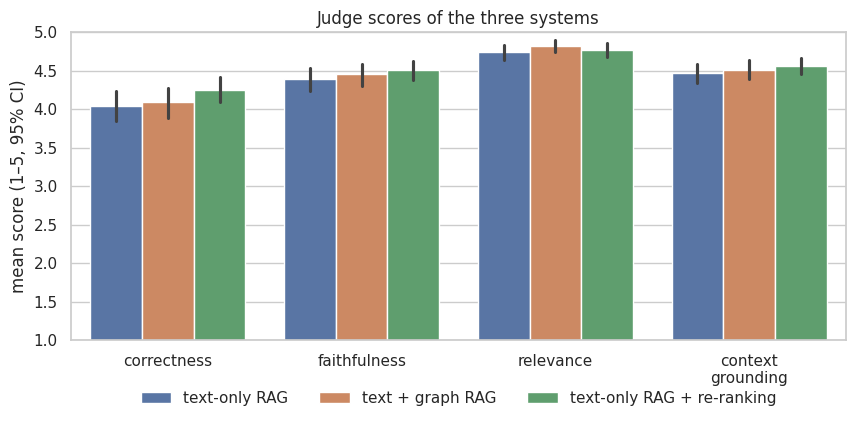

In [25]:
def paired_systems(a, b, criterion, mask=None, n=1000):
    wide = scores.pivot(index="id", columns="system", values=criterion).dropna(subset=[a, b])
    if mask is not None:
        wide = wide[wide.index.isin(mask)]
    d = (wide[a] - wide[b]).to_numpy()
    boots = d[np.random.default_rng(SEED).integers(0, len(d), (n, len(d)))].mean(axis=1)
    return {"questions": len(d), "mean difference": d.mean(), "low": np.percentile(boots, 2.5), "high": np.percentile(boots, 97.5),
            f"{a} better": (d > 0).mean(), f"{b} better": (d < 0).mean(), "p": (boots <= 0).mean()}

changed_prompt = set(BY_ID) - same_prompt
rows = []
for criterion in ["correctness", "faithfulness", "relevance", "context_grounding"]:
    for subset, mask in [("all questions", None), ("prompt changed by re-ranking", changed_prompt)]:
        rows.append({"comparison": "re-ranking vs text-only", "criterion": criterion, "subset": subset, **paired_systems("text+rerank", "text", criterion, mask)})
    rows.append({"comparison": "re-ranking vs text + graph", "criterion": criterion, "subset": "all questions", **paired_systems("text+rerank", "graph", criterion)})
enhancement = pd.DataFrame(rows)
enhancement.to_csv(OUT_DIR / "enhancement_paired.csv", index=False)
display(enhancement.set_index(["comparison", "criterion", "subset"]).round(3))

fig, ax = plt.subplots(figsize=(10, 4))
long = scores.melt(id_vars=["system"], value_vars=["correctness", "faithfulness", "relevance", "context_grounding"], var_name="criterion", value_name="score")
long["system"], long["criterion"] = long["system"].map(SYSTEMS_ALL), long["criterion"].str.replace("_", "\n")
sns.barplot(data=long, x="criterion", y="score", hue="system", hue_order=list(SYSTEMS_ALL.values()), ax=ax,
            palette=["#4C72B0", "#DD8452", "#55A868"], errorbar=("ci", 95))
ax.set(ylim=(1, 5), xlabel="", ylabel="mean score (1–5, 95% CI)", title="Judge scores of the three systems")
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
save_fig(fig, "enhancement_scores")

The re-ranked passages produce better answers with the same model and prompt: correctness rises from 4.04 to 4.25 over the text-only baseline, a paired difference of +0.22 with a 95% interval of [+0.00, +0.40] (p = 0.02), the one intervention in this part whose effect on correctness is reliable. The re-ranked system is also ahead of text + graph RAG (+0.16, [−0.03, +0.35], p = 0.06) and has the fewest refusals (15% against 22% and 16%). Faithfulness (+0.11) and context grounding (+0.09) move in the same direction without reaching significance, and relevance does not change (+0.03): re-ranking changes what the model is given, not how it answers. The re-ranker reordered the first six passages for every one of the 236 questions, so the comparison runs on all of them; the correctness score changed for 95 questions, 55 for the better and 40 for the worse.

The gain is concentrated where retrieval was the problem: the factoid questions go from 4.11 to 4.37 and their source article reaches the prompt more often (82% → 86%). The multi-hop questions do not improve (3.39 → 3.33) and the five global questions get worse (3.40 → 2.60): the share of multi-hop answers with a source article in the prompt drops from 78% to 61%. The mechanism is the one Section 3.6 predicted at the retrieval level: the cross-encoder rates each chunk alone, so for a question about two models the chunks about the more prominent one win the six slots, and the second article is pushed out. Precision for one topic is bought with coverage of several, which is the wrong trade for the categories the graph was meant to serve. With 18 and 5 questions these figures are fragile, but their direction is the same at the retrieval and the answer level.

### 3.6.2 Example: an answer changed by the enhancement

In [26]:
improved = (scores.pivot(index="id", columns="system", values="correctness").dropna(subset=["text", "text+rerank"])
            .assign(gain=lambda d: d["text+rerank"] - d["text"]).sort_values("gain", ascending=False))
if len(improved) and improved["gain"].iloc[0] > 0:
    qid = improved.index[0]
    q = BY_ID[qid]
    display(Markdown(f"**{qid} ({q['category']}, {q['type']})**: {q['question']}\n\n*Reference answer*: {q['reference_answer']}"))
    for system in ["text", "text+rerank"]:
        display(Markdown(f"*Judge correctness {judgments[(system, qid)]['scores']['correctness']}, faithfulness {judgments[(system, qid)]['scores']['faithfulness']}*"))
        show_answer(system, qid)
    print("Questions where re-ranking changed the correctness score:",
          f"{(improved['gain'] > 0).sum()} better, {(improved['gain'] < 0).sum()} worse, {(improved['gain'] == 0).sum()} same")

**q015 (factoid, factual)**: If I modify a Llama model, who owns the result?

*Reference answer*: You do: you own your modifications and derivative works of the Llama Materials, subject to Meta's ownership of the original Llama Materials and of derivatives made by or for Meta.

*Judge correctness 1, faithfulness 2*

**text-only RAG** · sources: [S1] meta-llama/Llama-3.2-3B-Instruct · Hugging Face (2024-09-18); [S2] Large Language Models for Commercial Use (2026-06-04); [S3] Meta now allows military agencies to access its AI (2024-11-11) … · graph facts: none

> If you modify a Llama model, you do not own the result; Meta owns the intellectual property rights to the original Llama model, and any modifications are still subject to Meta’s license terms. The license grants a non-exclusive, worldwide, non-transferable, and royalty-free limited license to use, reproduce, distribute, copy, create derivative works of, and make modifications to the Llama Materials [S1]. However, this license does not transfer ownership of the resulting derivative work to the user. Instead, the user retains only the right to use the modified model under the terms of the license, which includes obligations such as providing attribution and disclosing the use of Llama in any product or service derived from it [S5]. 

Moreover, the license includes limitations on commercial use, which implies that while users can modify the model, the resulting derivative work may not be used commercially without further permission or under conditions that do not fully satisfy open-source standards [S3]. Therefore, the ownership of the result of the modification remains with Meta, as the original intellectual property rights are retained by Meta Platforms, Inc. [S1][S5].

Thus, the result of modifying a Llama model is not owned by the user, but rather remains under Meta’s intellectual property rights as defined in the Llama license agreement.

*Judge correctness 5, faithfulness 5*

**text-only RAG + re-ranking** · sources: [S1] meta-llama/Llama-3.2-3B-Instruct · Hugging Face (2024-09-18); [S2] Meta now allows military agencies to access its AI (2024-11-11); [S3] Large Language Models for Commercial Use (2026-06-04) … · graph facts: none

> If you modify a Llama model, you are the owner of such derivative works and modifications, as stated in the license agreement between you and Meta [S1]. This means that, with respect to any derivative works and modifications of the Llama Materials that are made by you, you are and will be the owner of such derivative works and modifications [S1]. 

However, while you own the modified model, you must comply with Meta’s brand guidelines and provide proper attribution, such as including "Built with Llama" and "Llama 3.2 is licensed under the Llama 3.2 Community License" in any distribution [S4]. Additionally, if you create or distribute an AI model based on the Llama Materials, you must include "Llama" at the beginning of the model's name [S4].

It is important to note that although the license grants you ownership of the derivative work, it does not grant full commercial freedom—specific restrictions on commercial use and trademark usage remain in place [S2]. The Llama 3.2 Community License, while permissive in some aspects, still imposes conditions on how the model and its outputs are used, especially in commercial contexts [S1][S4].

Therefore, while you own the modified model, your use is subject to Meta’s licensing terms, including attribution and restrictions on commercial applications.

Questions where re-ranking changed the correctness score: 55 better, 40 worse, 141 same


## 3.7 Summary: Trade-offs and Insights for Trend Monitoring
The three systems answer the same 236 questions with the same language model, prompt and corpus; they differ only in which six passages, and which graph facts, the model is given.

| System | Correctness | Relevance | Refusals | Source in prompt | Cost per question |
|---|---|---|---|---|---|
| text-only RAG (Part 1) | 4.04 | 4.75 | 22% | 81% | one hybrid search |
| text + graph RAG (Part 2) | 4.09 | 4.82 | 16% | 82% | entity linking, graph lookup and fusion, plus the graph to build and maintain |
| text-only RAG + re-ranking (this part) | **4.25** | 4.77 | **15%** | **83%** | one hybrid search and one cross-encoder pass over 60 chunks (about 0.3 s on a GPU) |

**Trade-offs.** The knowledge graph buys a small, reliable gain in relevance and fewer refusals, and a gain in correctness that cannot be told from zero, at the price of the heaviest pipeline of the three. Its contribution is most visible on temporal and comparative questions, where the entity route brings the right articles into the ranking; it is absent on multi-hop questions and negative on analytical ones. Re-ranking buys a reliable gain in correctness for a modest cost, but only for questions that one article can answer; it harms the questions that need several. The text-only baseline is the cheapest and, with sparse search instead of hybrid, would be a stronger baseline than the one measured here.

**What RAG with a knowledge graph brings to trend monitoring in the open-models track.** The graph's value in this corpus is not the facts it stores, which are mostly of the kind *Nemotron-70B is a Nemotron model* and rarely answer a question on their own, but the way it *finds* articles: through the entities they mention rather than the words they share with the question. For monitoring a trend, where the question is "what has been written about X and the models built on it" rather than "what is X", that is the right mechanism, and the retrieval measurement shows it working. What limits it here is breadth: a ranking, with or without the graph, puts the most relevant chunks first, and for a question that spans five articles the most relevant chunks tend to come from the same one or two. The global questions therefore fail at retrieval, before the model or the graph facts can help (recall@10 of 0.14). The next step for a monitoring system is not a better graph but a different use of it: retrieve by entity, keep one passage per article, and summarise per article before answering, so that the breadth the graph can find survives into the prompt.

**Limitations**
- **The new categories are small.** 18 multi-hop and 5 global questions give correctness intervals of ±0.8, so the central question of the Q&A session, where graph RAG helps, is answered here with a direction and not with a measurement; the 213 factoid questions are the only category with a usable interval. The 30 drafted questions were what one reviewer could validate in the time available; the review dropped 7, and a set of 50 to 60 per new category would be needed to separate differences of the size observed (0.05–0.2).
- **Questions drafted from passages favour word matching.** Despite paraphrasing, the questions share about half of their content words with their passages (Section 3.1.1), which is why sparse search wins in Section 3.5 and why all absolute retrieval figures are optimistic. Questions written by readers, or from the articles' topics rather than their passages, would correct this.
- **The judge is a model, scored on its own terms.** The judge (GPT-5 mini) is a different model family from the RAG model, its scores are checked against a person on 30 answers (Section 3.4) and against itself at a higher reasoning effort (Section 3.4.1), and the comparisons are paired so that a bias common to both systems cancels. A bias that favours one system's style, for instance longer answers with more citations, would not be caught by the pairing, only by the human check.
- **One run of a 4B model at temperature 0.** The answers were generated once; the paired intervals account for the variation across questions but not for the variation of the generator across runs, which a second generation pass would show.
- **No global question was fully grounded.** None of the 5 had all its source articles in the prompt under either system, because retrieval found 14% of them in its first ten results. The prompt itself (6 passages, at most 2 per article, a Part 1 setting kept for comparability) is tight for a five-article question but not the binding limit; retrieval that favours diversity across articles would be the enhancement to try for this category, and was not.
- **The enhancement was evaluated against the text-only baseline it modifies.** Re-ranking the fused candidates of the graph system was not tested; the two could combine, since one widens the candidate set by entity and the other sharpens the order.

## 3.8 Saved Outputs
All outputs are saved in `OUT_DIR` on Google Drive (`HSLU/CLT/extraction_outputs/stage3/wp3`); the tables, sheets and figures are also copied to `artifacts/stage3_wp3/` in the repository.

| File | Content |
|---|---|
| `qa_multihop_draft.csv`, `qa_multihop_reviewed.xlsx`, `qa_multihop.json` | the new questions: the 30 drafted, the manual review, the 23 kept |
| `test_set_v2.json` | the full test set with the category of every question |
| `answers_wp3.jsonl` | the answers generated in this part (both systems on the new questions, enhanced system) |
| `judgments.jsonl`, `judge_scores.csv` | the judgments of every answer (scores, rationales, unsupported claims, flags) and the score table |
| `judge_paired.csv`, `enhancement_paired.csv` | paired comparisons of the systems with bootstrap intervals |
| `judge_check_sheet.xlsx`, `judge_agreement.csv` | human check of the judge: the blind sheet with the reviewer's scores (the system of each answer is in `judge_check_key.csv`, kept on Drive only), and the agreement |
| `judgments_high.jsonl`, `judge_effort.csv` | the same 30 answers judged at high reasoning effort, and the agreement between the two settings |
| `retrieval_variants.csv` | retrieval metrics of the Part 1 search and the enhancement variants |
| `figures/` | visualisations |

In [27]:
WP3_ART.mkdir(parents=True, exist_ok=True)
(WP3_ART / "figures").mkdir(exist_ok=True)
for f in OUT_DIR.iterdir():
    if f.suffix in {".csv", ".json", ".xlsx"} and f.stat().st_size < 5_000_000 and f.name != "judge_check_key.csv":
        shutil.copy(f, WP3_ART / f.name)
for f in FIG.glob("*.png"):
    shutil.copy(f, WP3_ART / "figures" / f.name)
for f in sorted(WP3_ART.rglob("*")):
    if f.is_file():
        print(f"{f.relative_to(REPO)}  ({f.stat().st_size / 1e3:.0f} kB)")

artifacts/stage3_wp3/enhancement_paired.csv  (2 kB)
artifacts/stage3_wp3/figures/enhancement_retrieval.png  (47 kB)
artifacts/stage3_wp3/figures/enhancement_scores.png  (51 kB)
artifacts/stage3_wp3/figures/judge_scores_by_category.png  (75 kB)
artifacts/stage3_wp3/figures/judge_scores_overall.png  (88 kB)
artifacts/stage3_wp3/figures/retrieval_and_correctness.png  (70 kB)
artifacts/stage3_wp3/judge_agreement.csv  (0 kB)
artifacts/stage3_wp3/judge_check_sheet.xlsx  (92 kB)
artifacts/stage3_wp3/judge_effort.csv  (1 kB)
artifacts/stage3_wp3/judge_paired.csv  (4 kB)
artifacts/stage3_wp3/judge_scores.csv  (51 kB)
artifacts/stage3_wp3/qa_multihop.json  (18 kB)
artifacts/stage3_wp3/qa_multihop_draft.csv  (125 kB)
artifacts/stage3_wp3/qa_multihop_reviewed.xlsx  (58 kB)
artifacts/stage3_wp3/retrieval_variants.csv  (0 kB)
artifacts/stage3_wp3/test_set_v2.json  (114 kB)


### AI assistance Disclosure
- **Multi-hop and global questions**: Claude Opus 5 (Anthropic) drafted the 30 new questions and reference answers from the Part 1 passages, grouped by model family and event, with one evidence sentence per passage, as in Part 1; the brief requires the Q&A pairs to be generated by an LLM different from the RAG model. Claude also computed the three measurements of the review sheet (answer coverage, single-passage coverage, wording overlap) and flagged the questions it found problematic. Every question was then reviewed by the team member, who kept 20, edited 3 and dropped 7; the decisions differ from Claude's own assessment on 3 questions.
- **Judge model**: GPT-5 mini (OpenAI) scored the 708 answers on the five criteria through the `score_rag_answer` tool of the course toolbox; its scores were checked against the team member's scores on a blind sample (Section 3.4).
- **Coding assistant**: Claude wrote and debugged the notebook code, including the rebuild of the Part 2 graph retriever from the repository, and tested it on a local mock of the pipeline before the Colab runs.
- **Writing**: Claude drafted the markdown texts from the outputs of the executed notebook; the team member checked every figure quoted in them against the notebook's tables and edited the texts. All interpretations refer to outputs that are in the notebook.